# Домашнее задание 2. Вариант NLP: NER - детекция в тексте

**Дедлайн:** вс 22.11.2026, 23:59

В ДЗ2 вы выбираете **один** вариант: CV (детекция объектов на YOLO) или NLP (этот ноутбук). Номера задач и баллы в вариантах совпадают. NER (named entity recognition) - это детекция в тексте: найти спаны, т.е. непрерывные куски из слов, и для каждого предсказать тип сущности. Вы берете предобученный энкодер с Hugging Face Hub, находите свой датасет, приводите разметку к формату модели, дообучаете, считаете метрики и разбираете ошибки.

- Заполняйте места с `# ваш код` и ячейки «**Ответ:**». Сигнатуры функций и открытые тесты не меняйте, свои ячейки добавлять можно. Открытые тесты проверяют часть контракта, при проверке будут и другие входы
- В ответах опирайтесь на свои числа: наблюдение, объяснение, ограничение вывода. Обычно хватает 2-4 предложений. Отсутствие ожидаемого эффекта - нормальный результат, если эксперимент корректный и вы это обсудили
- Свой код обязателен в 1.2 (параметры по блокам), 2.2 (конвертация разметки + тесты), 3.1 (словарный бейзлайн), 5.1 (категоризация ошибок). Для обучения и стандартных метрик можно `transformers` (`Trainer` или свой цикл) и `seqeval`
- `FAST_MODE = True` - отладка на маленьком подмножестве, весь ноутбук не дольше 5 минут на T4. Финальный прогон - с `FAST_MODE = False`, ориентир до ~1 часа на T4. Бонусы включаются через `BONUS_TASKS`, выключенные бонусы пропускаются, даже если их ячейки пустые
- Запуск: Colab (T4) или Kaggle (GPU T4, ноутбук сам берет одну карту). Зависимости ставит первая ячейка, пины те же, что в `requirements_nlp.txt`. Укажите устройство в ячейке ниже, время обучения возвращает ваш `train_ner` (4.1)
- Только открытые модели и данные. Лицензию модели и датасета укажите в 1.1 и 2.1
- Можно документацию, материалы курса и код семинаров - укажите источник
- Сдача как в ДЗ1: PR в свой публичный GitHub-репозиторий, ссылка на него - в Google-форму (ссылку на форму дадим отдельно). В PR - ноутбук с outputs и `artifacts/metrics.json` (пишется в 5.3, перед бонусами). Датасет (`data/`), `runs/` и веса моделей не кладите, достаточно кода скачивания; файл доразметки из 6.1 - кладите
- Для полной сдачи: Restart & Run All с `FAST_MODE = False`, сохранить outputs. Если сдаете частичное решение, перечислите нерешенные задачи в ячейке ниже и приложите то, что получилось. Ошибки не скрывайте: баллы ставятся по задачам, одна ошибка не обнуляет остальные
- ДЗ индивидуальное

| раздел | задачи | баллы |
|---|---|---|
| 1. Модель | 1.1 модель и ревизия · 1.2 архитектура | 4 |
| 2. Данные | 2.1 датасет · 2.2 формат разметки | 4 |
| 3. Бейзлайн | 3.1 бейзлайн до дообучения | 2 |
| 4. Дообучение | 4.1 обучение · 4.2 метрики | 6 |
| 5. Анализ | 5.1 разбор ошибок · 5.2 абляция · 5.3 выводы | 4 |
| 6*. Бонусы | 6.1 доразметка · 6.2 другая модель · 6.3 сдвиг · 6.4 экспорт и скорость · 6.5 пороги | до +4 из 5.5 |
| итого | | 20 + 4 |

Соответствие с CV-вариантом - задачи те же, меняется «геометрия»: вместо прямоугольника на картинке - отрезок из слов в предложении.

| CV (детекция на картинке) | NLP (NER в тексте) |
|---|---|
| бокс | спан: (начало, конец, тип) в индексах слов |
| класс объекта | тип сущности (PER, ORG, LOC, ...) |
| фон | тег `O` |
| VOC / COCO -> YOLO-формат | слова и спаны -> BIO-теги под сабворды токенизатора |
| backbone -> neck -> head | эмбеддинги -> слои энкодера -> голова token classification |
| mAP по IoU | F1 по сущностям (`seqeval`, спан засчитывается при точном совпадении границ и типа) |
| ошибка локализации (IoU 0.1-0.5) | ошибка границы спана (тип верный, спаны пересекаются) |
| ошибка класса | ошибка типа |
| пропуск / лишний бокс | пропуск / лишний спан |
| порог conf | порог уверенности спана |

Внутренности трансформера (attention, устройство слоя энкодера) - тема ДЗ3. Здесь энкодер рассматривается на уровне блоков.

Примерный план: первая неделя - разделы 1-3 (модель, датасет, разметка, бейзлайн), вторая - обучение, метрики, разбор ошибок, абляция и финальный прогон.

**Сведения о сдаче.** Укажите устройство (Colab T4 / Kaggle / свое), выбранные модель и датасет (ссылка и лицензия), бонусы, внешние источники и нерешенные задачи (если есть).

**Ответ:** Модель — [RuBERT base](https://huggingface.co/ai-forever/ruBert-base) (Apache 2.0). Датасет — [Collection3](https://huggingface.co/datasets/RCC-MSU/collection3) (лицензия `other` в карточке), описание разметки — [на сайте авторов](https://labinform.ru/pub/named_entities/index.htm).
Локальный прогон на NVIDIA GeForce RTX 3050 Laptop GPU с `FAST_MODE=False`. Выполнены 1.1–5.3. Включены бонусы 6.1–6.5.

In [ ]:
# Зависимости (пины те же, что в requirements_nlp.txt). Запускайте эту ячейку первой, тогда перезапуск сессии не нужен
# Безвредный шум: строки ERROR от pip про bigframes / cudf / pyarrow на Kaggle и предупреждение про HF_TOKEN ниже (токен не нужен)
# Локально: сначала torch под свою платформу (https://pytorch.org/get-started/locally/)
%pip install -q "torch>=2.4" "transformers==5.22.1" "datasets==5.1.0" "accelerate==1.15.0" "seqeval==1.2.2" numpy matplotlib onnx onnxruntime onnxscript

In [1]:
import os
os.environ.setdefault('CUDA_VISIBLE_DEVICES', '0')   # одна GPU: на Kaggle T4 x2 иначе Trainer включит DataParallel (медленнее и хуже)
import collections
import copy
import json
import math
import random
import re
import time
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import torch

import datasets
import transformers
from datasets import DatasetDict, load_dataset
from huggingface_hub import HfApi
from seqeval.metrics import classification_report, f1_score, precision_score, recall_score
from transformers import (AutoModelForTokenClassification, AutoTokenizer, DataCollatorForTokenClassification,
                          Trainer, TrainingArguments)

transformers.logging.set_verbosity_error()
plt.rcParams['figure.dpi'] = 100
plt.rcParams['font.size'] = 11

print(f'torch {torch.__version__}, transformers {transformers.__version__}, datasets {datasets.__version__}')
print(f'CUDA available: {torch.cuda.is_available()}')

torch 2.11.0+cu128, transformers 5.22.1, datasets 5.1.0
CUDA available: True


W1122 22:11:31.638000 25228 cuda-venv\Lib\site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


In [2]:
def get_device():
    if torch.cuda.is_available():
        return torch.device('cuda')
    if torch.backends.mps.is_available():
        return torch.device('mps')
    return torch.device('cpu')


def set_seed(seed=0):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    transformers.set_seed(seed)


device = get_device()
DEVICE_NAME = torch.cuda.get_device_name(0) if device.type == 'cuda' else device.type
set_seed(0)
print(device, DEVICE_NAME)

cuda NVIDIA GeForce RTX 3050 Laptop GPU


In [3]:
FAST_MODE = False   # True - отладка, False - финальный прогон
BONUS_TASKS = {'6.1', '6.2', '6.3', '6.4', '6.5'}
assert BONUS_TASKS <= {'6.1', '6.2', '6.3', '6.4', '6.5'}

SEED = 0
N_TRAIN = 2000 if FAST_MODE else None   # None - весь train
N_EVAL = 500 if FAST_MODE else None     # подмножество validation и test в FAST_MODE
EPOCHS = 1 if FAST_MODE else 3
MAX_LENGTH = 128                        # длина в сабвордах, длиннее - обрезается
ARTIFACTS = Path('artifacts')
ARTIFACTS.mkdir(exist_ok=True)
RUN_TIMES = {}
bonus_results = {}

---
# 1. Модель

## 1.1 Модель и ревизия (1.5 балла)

Выберите предобученный энкодер на Hugging Face Hub, подходящий под язык и домен вашего датасета. Модель на Hub - это git-репозиторий: владелец может перезалить веса, токенизатор или конфиг, и `main` начнет указывать на другую версию. Поэтому зафиксируйте `revision` - полный commit hash (40 символов). Его видно во вкладке «Files and versions» -> «History» или через `HfApi().model_info(MODEL_ID).sha`.

Ориентиры для выбора (не исчерпывающий список):
- русский: `cointegrated/rubert-tiny2` (29M параметров, быстрый), `DeepPavlov/rubert-base-cased` (~180M)
- многоязычные: `FacebookAI/xlm-roberta-base` (~280M), `google-bert/bert-base-multilingual-cased` (~180M), `distilbert/distilbert-base-multilingual-cased`
- английский: `google-bert/bert-base-cased`, `FacebookAI/roberta-base` (в 1.1 задайте `TOKENIZER_KWARGS = {'add_prefix_space': True}`), `microsoft/deberta-v3-small`
- биомедицина: `dmis-lab/biobert-base-cased-v1.2`

Нужен fast-токенизатор: `word_ids()`, без которого не выровнять метки по сабвордам, есть только у него. На T4 модель до ~300M параметров дообучается на датасете в десятки тысяч предложений за минуты - десятки минут.

Нужен базовый энкодер, а не модель, уже дообученная на NER: с ней 3.1 и 4.1 теряют смысл.

In [4]:
MODEL_ID = 'ai-forever/ruBert-base'
REVISION = '05f37a2ca9e333fd18f30cd0c96c68d274793c69'
TOKENIZER_KWARGS = {}   # для roberta-base: {'add_prefix_space': True}

In [5]:
assert MODEL_ID, 'укажите MODEL_ID'
assert re.fullmatch(r'[0-9a-f]{40}', REVISION or ''), 'REVISION - полный commit hash из 40 символов, а не main и не тег'
info = HfApi().model_info(MODEL_ID, revision=REVISION, files_metadata=True)
card = info.card_data.to_dict() if info.card_data else {}
weights = {s.rfilename: f'{s.size / 2**20:.0f} MB' for s in info.siblings if s.rfilename.endswith(('.safetensors', '.bin'))}
print(f'model:    {MODEL_ID}\nrevision: {info.sha}\nlicense:  {card.get("license")}\nlanguage: {card.get("language")}')
print(f'updated:  {info.last_modified}\nweights:  {weights}')

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, revision=REVISION, **TOKENIZER_KWARGS)
assert tokenizer.is_fast, 'нужен fast-токенизатор: word_ids() есть только у него'
print(type(tokenizer).__name__, 'vocab size', tokenizer.vocab_size)
print(tokenizer.tokenize('Петр Ильич Чайковский родился в Воткинске'))

model:    ai-forever/ruBert-base
revision: 05f37a2ca9e333fd18f30cd0c96c68d274793c69
license:  apache-2.0
language: ['ru']
updated:  2023-11-03 12:50:38+00:00
weights:  {'pytorch_model.bin': '683 MB'}
BertTokenizer vocab size 120138
['пет', '##р', 'иль', '##ич', 'ча', '##ик', '##ов', '##ски', '##и', 'родился', 'в', 'вот', '##кинс', '##ке']


**Вопрос.** Почему вы выбрали эту модель: язык и данные предобучения, размер и скорость, ожидаемое качество на NER, лицензия? Сравните с 1-2 альтернативами из списка выше: размер, язык, скорость, качество по карточке. Что может сломаться в вашем ноутбуке через полгода, если не фиксировать `revision`?

**Ответ:** Выбрал RuBERT для русских новостей. Он предобучен на 30 ГБ русских текстов, имеет 178 млн параметров и распространяется под Apache 2.0, поэтому подходит по языку и укладывается в ориентир по размеру для T4.
RuBERT-tiny2 (29 млн) быстрее, а в его карточке упор на качество векторов предложений. Многоязычный XLM-R (278 млн) крупнее и в сравнении по NER обходит mBERT, а F1 RuBERTа на наших новостях проверим потом

## 1.2 Архитектура (2.5 балла)

Энкодер для token classification на уровне блоков:

1. **эмбеддинги** - сабворд -> вектор размера hidden (таблица `vocab_size x hidden`) + позиционные эмбеддинги (у DeBERTa их нет, позиции учитываются в attention) и type-эмбеддинги (у BERT-подобных), LayerNorm, dropout. Выход `(B, T, H)`
2. **N слоев энкодера** - одинаковые по форме блоки `(B, T, H) -> (B, T, H)`, в которых токены обмениваются информацией друг с другом. Устройство слоя (attention, FFN) - ДЗ3
3. **голова token classification** - dropout + `Linear(H, K)` к каждому токену независимо, K - число BIO-тегов. Выход - logits `(B, T, K)`
4. **сборка спанов** - argmax по тегам на первом сабворде каждого слова, затем BIO -> спаны (это уже не нейросеть, а ваш код из 2.2)

Ниже модель создается с головой на `N_DEMO_LABELS = 7` тегов (O + B/I для трех типов), под ваш датасет голову пересоздает `make_model` (3.1, 4.1).

1. Реализуйте `params_by_block(model)` - число параметров по блокам: `embeddings`, `encoder` (все слои), `head` (классификатор), `other` (все остальное: у BERT и RoBERTa для token classification здесь 0, у DeBERTa - `encoder.rel_embeddings` и общий `encoder.LayerNorm`) и `layers` - список по слоям энкодера. Сумма блоков должна совпасть с общим числом параметров
2. Прогоните dummy-вход `demo_texts` (батч из двух предложений, уже разбитых на слова) через токенизатор и модель с `output_hidden_states=True`, сохраните результат токенизатора в `enc`, выход модели в `out` и выведите формы: `input_ids`, `attention_mask`, все `hidden_states`, `logits`

In [6]:
N_DEMO_LABELS = 7
demo_model = AutoModelForTokenClassification.from_pretrained(MODEL_ID, revision=REVISION, num_labels=N_DEMO_LABELS)
cfg = demo_model.config
print({k: getattr(cfg, k, None) for k in ['model_type', 'vocab_size', 'hidden_size', 'num_hidden_layers',
                                          'num_attention_heads', 'intermediate_size', 'max_position_embeddings']})
for name, module in demo_model.named_children():
    print(f'{name:<12} {type(module).__name__}')

{'model_type': 'bert', 'vocab_size': 120138, 'hidden_size': 768, 'num_hidden_layers': 12, 'num_attention_heads': 12, 'intermediate_size': 3072, 'max_position_embeddings': 512}
bert         BertModel
dropout      Dropout
classifier   Linear



Loading weights: 100%|##########| 197/197 [00:00<00:00, 36363.06it/s]


In [7]:
def params_by_block(model):
    # -> {'embeddings': int, 'encoder': int, 'head': int, 'other': int, 'layers': [int, ...]}
    backbone = model.base_model
    embeddings = sum(p.numel() for p in backbone.embeddings.parameters())
    layers = [sum(p.numel() for p in layer.parameters()) for layer in backbone.encoder.layer]
    encoder = sum(layers)
    head = sum(p.numel() for p in model.classifier.parameters())
    total = sum(p.numel() for p in model.parameters())

    return {
        'embeddings': embeddings,
        'encoder': encoder,
        'head': head,
        'other': total - embeddings - encoder - head,
        'layers': layers,
    }

In [8]:
blocks = params_by_block(demo_model)
total = sum(p.numel() for p in demo_model.parameters())
assert sum(blocks[k] for k in ['embeddings', 'encoder', 'head', 'other']) == total
assert blocks['head'] == cfg.hidden_size * N_DEMO_LABELS + N_DEMO_LABELS
assert len(blocks['layers']) == cfg.num_hidden_layers and sum(blocks['layers']) == blocks['encoder'], \
    'encoder - сумма слоев, все вне слоев (например, rel_embeddings у DeBERTa) - в other'
assert blocks['embeddings'] >= cfg.vocab_size * cfg.hidden_size
for k in ['embeddings', 'encoder', 'head', 'other']:
    print(f'{k:<11}{blocks[k]:>13,}  {blocks[k] / total:6.1%}')
print(f'{"total":<11}{total:>13,}\nper layer: {blocks["layers"]}')

embeddings    92,662,272   52.1%
encoder       85,054,464   47.9%
head               5,383    0.0%
other                  0    0.0%
total        177,722,119
per layer: [7087872, 7087872, 7087872, 7087872, 7087872, 7087872, 7087872, 7087872, 7087872, 7087872, 7087872, 7087872]


In [9]:
demo_texts = [['Петр', 'Чайковский', 'родился', 'в', 'Воткинске', '.'],
              ['ITMO', 'University', 'is', 'in', 'Saint', 'Petersburg']]

enc = tokenizer(demo_texts, is_split_into_words=True, padding=True, return_tensors='pt')
demo_model.eval()
with torch.inference_mode():
    out = demo_model(**enc, output_hidden_states=True)

print('input_ids:', tuple(enc['input_ids'].shape))
print('attention_mask:', tuple(enc['attention_mask'].shape))
for index, hidden in enumerate(out.hidden_states):
    print(f'hidden_states[{index}]:', tuple(hidden.shape))
print('logits:', tuple(out.logits.shape))

input_ids: (2, 15)
attention_mask: (2, 15)
hidden_states[0]: (2, 15, 768)
hidden_states[1]: (2, 15, 768)
hidden_states[2]: (2, 15, 768)
hidden_states[3]: (2, 15, 768)
hidden_states[4]: (2, 15, 768)
hidden_states[5]: (2, 15, 768)
hidden_states[6]: (2, 15, 768)
hidden_states[7]: (2, 15, 768)
hidden_states[8]: (2, 15, 768)
hidden_states[9]: (2, 15, 768)
hidden_states[10]: (2, 15, 768)
hidden_states[11]: (2, 15, 768)
hidden_states[12]: (2, 15, 768)
logits: (2, 15, 7)


In [10]:
B, T = enc['input_ids'].shape
assert B == 2 and out.logits.shape == (B, T, N_DEMO_LABELS)
assert len(out.hidden_states) == cfg.num_hidden_layers + 1
assert all(h.shape == (B, T, cfg.hidden_size) for h in out.hidden_states)

# скорость прямого прохода: батч 32 предложения x 62 слова (сколько это сабвордов - см. вывод)
x = {k: v.to(device) for k, v in tokenizer([['слово'] * 62] * 32, is_split_into_words=True, return_tensors='pt').items()}
demo_model.to(device).eval()
with torch.inference_mode():
    demo_model(**x)
    if device.type == 'cuda':
        torch.cuda.synchronize()
    start = time.perf_counter()
    for _ in range(5):
        demo_model(**x)
    if device.type == 'cuda':
        torch.cuda.synchronize()
print(f'forward 32 x {x["input_ids"].shape[1]}: {(time.perf_counter() - start) / 5 * 1000:.1f} ms на {DEVICE_NAME}')
demo_model = demo_model.cpu()

forward 32 x 64: 97.6 ms на NVIDIA GeForce RTX 3050 Laptop GPU


**Вопрос.** Опишите путь входа по блокам с формами тензоров из вашего вывода. Какой блок содержит больше всего параметров и почему? В каком блоке токены обмениваются информацией, а где каждый токен обрабатывается независимо? Почему `T` в logits больше числа слов?

**Ответ:** Токенизатор выдаёт ID токенов и маску формы `(2, T)`. Эмбеддинги превращают каждый токен в вектор из 768 чисел, 12 слоёв обновляют эти векторы с сохранением формы `(2, T, 768)`, а голова выдаёт 7 логитов для каждого токена, то есть `(2, T, 7)`.
Больше всего параметров в эмбеддингах (92,7 млн из 177,7 млн), потому что в словаре 120 138 токенов и каждому нужен вектор из 768 чисел.
Токены обмениваются информацией в self-attention, а FFN и классификатор обрабатывают каждый токен отдельно. `T` больше числа слов из-за сабвордов, спецтокенов и паддинга.

---
# 2. Данные

## 2.1 Датасет (1.5 балла)

Найдите датасет для NER на Hugging Face Hub или в другом открытом источнике, подходящий под вашу модель по языку. Опишите источник, лицензию, как размечали, типы сущностей, размер и сплиты; посчитайте статистику: число сущностей каждого типа по сплитам, распределение длин спанов (в словах), длины предложений.

**Нельзя брать WikiANN ru** (`unimelb-nlp/wikiann`, конфиг `ru`) - на нем ниже показан пример формата. Другие языки WikiANN брать можно.

Подсказки - датасеты, которые на момент выдачи загружаются текущей библиотекой `datasets` (проверено 31.10.2026, `datasets` 5.1). Библиотека больше не исполняет loading-скрипты, поэтому часть датасетов грузится из служебной ветки с parquet-версией - так, как написано в списке:

Русский:
- `Babelscape/wikineural` - WikiNEuRal, PER / ORG / LOC / MISC, 9 языков; для русского сплиты `train_ru`, `val_ru`, `test_ru`; CC BY-NC-SA 4.0
- `Babelscape/multinerd` - MultiNERD, 15 типов, 10 языков, колонка `lang` - отфильтруйте `ru`; CC BY-NC-SA 4.0
- `load_dataset('RCC-MSU/collection3', revision='refs/convert/parquet')` - Collection3, новости, PER / ORG / LOC, уже `tokens` + `ner_tags`
- `undefinedhorizons/nerus_lenta` - Nerus: новости Lenta.ru с автоматической разметкой PER / LOC / ORG, только `train` и очень большой - возьмите подмножество и сами отделите validation и test
- `gusevski/factrueval2016` - FactRuEval-2016, новости; вся разметка в одной вложенной колонке `data` - разобрать в предложения, слова и BIO
- `load_dataset('iluvvatar/RuNNE', revision='refs/convert/parquet')` и то же для `iluvvatar/NEREL` - новости, 29 типов, вложенные сущности, спаны по символам в тексте. Нужны разбиение на предложения и слова (целый текст длиннее `MAX_LENGTH = 128` сабвордов, хвост обрежется), BIO и правило для вложенных (например, оставить только внешние) - самая содержательная конвертация из списка

Другие языки:
- `unimelb-nlp/wikiann` - WikiANN, 176 языков (любой, кроме `ru`), PER / ORG / LOC
- `lhoestq/conll2003`, `tomaarsen/conll2003` или `load_dataset('eriktks/conll2003', revision='refs/convert/parquet')` - CoNLL-2003, английский, PER / ORG / LOC / MISC
- `DFKI-SLT/few-nerd`, конфиг `supervised` - Few-NERD, английский, 8 крупных и 66 мелких типов; теги в IO-схеме (без `B-` и `I-`) - переведите в BIO; CC BY-SA 4.0
- `load_dataset('tner/wnut2017', revision='refs/convert/parquet')` - WNUT-17, соцсети, редкие и новые сущности; имена тегов - в файле `dataset/label.json` репозитория

Биомедицина (английский):
- `load_dataset('ncbi/ncbi_disease', revision='refs/convert/parquet')` - NCBI-disease, один тип Disease
- `load_dataset('tner/bc5cdr', revision='refs/convert/parquet')` - BC5CDR, Chemical / Disease, теги в колонке `tags`: `{"O": 0, "B-Chemical": 1, "B-Disease": 2, "I-Disease": 3, "I-Chemical": 4}`

Если `load_dataset('<id>')` падает из-за loading-скрипта, берите ветку `revision='refs/convert/parquet'` (как в списке) или сырые файлы: `load_dataset('json', data_files='hf://datasets/<id>/<путь к файлу>')`. Датасеты из списка разрешены, лицензию укажите, как в карточке.

Если сплита validation или test нет, отделите их сами (`train_test_split` с фиксированным seed). Если датасет очень большой, возьмите подмножество и укажите это.

Контракт для остального ноутбука (после 2.2): `raw` - `DatasetDict` со сплитами `train`, `validation`, `test`, у каждого примера `tokens` (список слов) и `ner_tags` (список id тегов той же длины); `LABEL_NAMES` - список BIO-тегов, `LABEL_NAMES[i]` - тег с id `i`, тег `O` обязателен.

Если у `ner_tags` нет имен тегов (в `features` список чисел, а не `ClassLabel`; так у WikiNEuRal, MultiNERD и `lhoestq/conll2003`), составьте `LABEL_NAMES` вручную по карточке датасета. Например, у WikiNEuRal: `['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC', 'B-MISC', 'I-MISC']`.

In [11]:
# пример формата на WikiANN ru (этот датасет брать нельзя)
example = load_dataset('unimelb-nlp/wikiann', 'ru', split='validation[:3]')
print(example)
print(example.features['ner_tags'].feature.names)
for ex in example:
    print(list(zip(ex['tokens'], ex['ner_tags'])), ex['spans'])

Dataset({
    features: ['tokens', 'ner_tags', 'langs', 'spans'],
    num_rows: 3
})
['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC']
[('Отличился', 0), ('во', 0), ('время', 0), ('боёв', 0), ('в', 0), ('Германии', 5), ('.', 0)] ['LOC: Германии']
[('1920—1922', 0), ('—', 0), ('техник', 0), ('военно-гидротехнического', 0), ('отряда', 0), ('(', 0), ('Чернигов', 5), (')', 0), (',', 0)] ['LOC: Чернигов']
[('Нагибин', 1), (',', 2), ('Владимир', 2), ('Владимирович', 2)] ['PER: Нагибин , Владимир Владимирович']


In [12]:
DATASET_ID, DATASET_CONFIG = 'RCC-MSU/collection3', None
raw = load_dataset(DATASET_ID, DATASET_CONFIG, revision='refs/convert/parquet')

tag_feature = raw['train'].features['ner_tags'].feature
LABEL_NAMES = list(getattr(tag_feature, 'names', ['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC']))
print(raw)
print('Метки по ID:', dict(enumerate(LABEL_NAMES)))

DatasetDict({
    train: Dataset({
        features: ['id', 'tokens', 'ner_tags'],
        num_rows: 9301
    })
    validation: Dataset({
        features: ['id', 'tokens', 'ner_tags'],
        num_rows: 2153
    })
    test: Dataset({
        features: ['id', 'tokens', 'ner_tags'],
        num_rows: 1922
    })
})
Метки по ID: {0: 'O', 1: 'B-PER', 2: 'I-PER', 3: 'B-ORG', 4: 'I-ORG', 5: 'B-LOC', 6: 'I-LOC'}


Сплит          Строк   Спанов     PER     ORG     LOC
train           9301    18247    7406    5960    4881
validation      2153     4117    1641    1308    1168
test            1922     4001    1570    1256    1175
train — спаны, длина в словах → число сущностей: {1: 9025, 2: 6124, 3: 2068, 4: 373, 5: 206, 6: 238, 7: 71, 8: 68, 9: 21, 10: 24, 11: 10, 12: 4, 13: 6, 14: 2, 15: 3, 16: 3, 18: 1}
train — длина строки в словах: медиана 18, P90 35, максимум 256
validation — спаны, длина в словах → число сущностей: {1: 2110, 2: 1344, 3: 453, 4: 81, 5: 43, 6: 52, 7: 13, 8: 11, 9: 6, 10: 2, 12: 1, 13: 1}
validation — длина строки в словах: медиана 18, P90 35, максимум 118
test — спаны, длина в словах → число сущностей: {1: 1951, 2: 1306, 3: 540, 4: 86, 5: 31, 6: 55, 7: 11, 8: 9, 9: 5, 10: 4, 11: 3}
test — длина строки в словах: медиана 19, P90 36, максимум 122


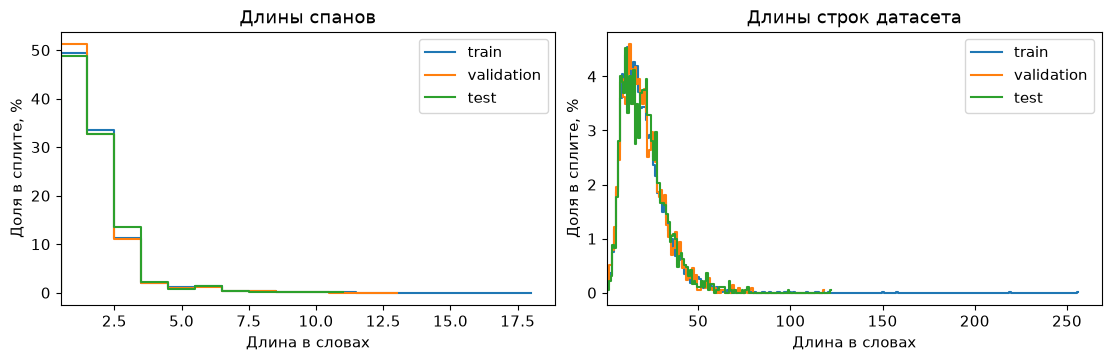

In [13]:
from seqeval.metrics.sequence_labeling import get_entities

entity_types = [tag[2:] for tag in LABEL_NAMES if tag.startswith('B-')]
lengths_by_split = {}

print(f'{"Сплит":<12}{"Строк":>8}{"Спанов":>9}' + ''.join(f'{kind:>8}' for kind in entity_types))
for split in ('train', 'validation', 'test'):
    entity_counts = collections.Counter()
    span_lengths = []
    sentence_lengths = []

    for example in raw[split]:
        sentence_lengths.append(len(example['tokens']))
        tags = [LABEL_NAMES[tag_id] for tag_id in example['ner_tags']]
        for kind, start, end in get_entities(tags):
            entity_counts[kind] += 1
            span_lengths.append(end - start + 1)  # get_entities включает правую границу

    lengths_by_split[split] = (span_lengths, sentence_lengths)
    count_columns = ''.join(f'{entity_counts[kind]:>8}' for kind in entity_types)
    print(f'{split:<12}{len(sentence_lengths):>8}{len(span_lengths):>9}{count_columns}')

for split, (span_lengths, sentence_lengths) in lengths_by_split.items():
    print(f'{split} — спаны, длина в словах → число сущностей:',
          dict(sorted(collections.Counter(span_lengths).items())))
    p50, p90 = np.percentile(sentence_lengths, [50, 90])
    print(f'{split} — длина строки в словах: медиана {p50:g}, P90 {p90:g}, максимум {max(sentence_lengths)}')

fig, (span_ax, sentence_ax) = plt.subplots(1, 2, figsize=(11, 3.5), layout='constrained')
for split, (span_lengths, sentence_lengths) in lengths_by_split.items():
    for ax, lengths in ((span_ax, span_lengths), (sentence_ax, sentence_lengths)):
        counts = np.bincount(lengths)
        ax.step(np.arange(len(counts)), counts * (100 / len(lengths)), where='mid', label=split)

for ax, title in ((span_ax, 'Длины спанов'), (sentence_ax, 'Длины строк датасета')):
    ax.set(title=title, xlabel='Длина в словах', ylabel='Доля в сплите, %', xlim=(0.5, None))
    ax.legend()
plt.show()

**Вопрос.** Откуда датасет, под какой лицензией и как его размечали (вручную, автоматически, полуавтоматически)? Какие типы сущностей, сколько их по сплитам, какие типы редкие? Какие особенности данных (длина спанов, длина предложений, шум разметки) могут повлиять на обучение?

**Ответ:** Collection3 вырос из тысячи русскоязычных новостей Persons-1000. Размечали их вручную в Brat, сверяли разметку с предсказаниями системы, исправляли ошибки. Лицензия указана как `other`, без подробных условий.
В train 9301 пример, в validation 2153, в test 1922. Число упоминаний каждого типа по сплитам - в таблице. По всему корпусу реже всего встречается `LOC` (около 7к мест), затем `ORG` (8к организаций) и `PER` (11к людей).
У длинной сущности легче ошибиться в границе, а у длинного предложения токенизатор может обрезать часть названия

## 2.2 Формат разметки (2.5 балла)

Модель предсказывает тег для каждого **сабворда**, а разметка дана по **словам** (или спанами по символам). Нужны две конвертации и тесты к ним.

1. `bio_to_spans(tags)` - BIO-теги слов -> список спанов `(start, end, type)`, `end` не включается. `B-X` начинает спан, `I-X` продолжает спан того же типа, иначе начинает новый (так делает `seqeval` в режиме по умолчанию), `O` закрывает спан. Тип может содержать дефис (`B-art-film` -> `art-film`)
2. `spans_to_bio(spans, n_words)` - обратно: спаны -> BIO-теги длины `n_words`
3. `align_labels(word_labels, word_ids, b_to_i=None)` - метки слов -> метки сабвордов. `word_ids` - выход `tokenizer(...).word_ids(i)`: номер слова для каждого сабворда, `None` у спецтокенов. По умолчанию метка слова ставится на его первый сабворд, спецтокены и продолжения слова получают `-100` (cross-entropy их игнорирует). Если передан словарь `b_to_i` (id тега `B-X` -> id тега `I-X`), метку получают все сабворды слова, у продолжений `B-X` заменяется на `I-X` - это вариант для абляции 5.2

Если ваш датасет не в формате «слова + BIO» (спаны по символам, IO-теги, CoNLL-текст), сначала приведите его к контракту из 2.1 и проверьте конвертацию на примерах глазами. Если датасет уже в BIO, сделайте обратную конвертацию: BIO -> спаны в JSON (`data/<split>_spans.jsonl`), прочитайте файл обратно, сконвертируйте в BIO и проверьте, что получилось то же самое (если в исходнике есть `I-X` без `B-X`, дословно не совпадет: сравните спаны и посчитайте такие предложения).

In [14]:
def bio_to_spans(tags):
    # ['B-PER', 'I-PER', 'O', 'B-LOC'] -> [(0, 2, 'PER'), (3, 4, 'LOC')]
    spans = []
    start = entity_type = None

    for index, tag in enumerate(tags):
        prefix, _, kind = tag.partition('-')
        if tag != 'O' and (prefix not in ('B', 'I') or not kind):
            raise ValueError(f'Некорректный BIO-тег: {tag!r}')
        if prefix == 'I' and kind == entity_type:
            continue

        if entity_type is not None:
            spans.append((start, index, entity_type))
        start, entity_type = (None, None) if tag == 'O' else (index, kind)

    if entity_type is not None:
        spans.append((start, len(tags), entity_type))
    return spans


def spans_to_bio(spans, n_words):
    # [(0, 2, 'PER')], 3 -> ['B-PER', 'I-PER', 'O']
    if n_words < 0:
        raise ValueError('Число слов должно быть неотрицательным')
    tags = ['O'] * n_words
    for start, end, kind in spans:
        if not 0 <= start < end <= n_words:
            raise ValueError(f'Спан вне допустимых границ: {(start, end, kind)}')
        if any(tag != 'O' for tag in tags[start:end]):
            raise ValueError(f'Спан пересекается с другим: {(start, end, kind)}')
        tags[start] = f'B-{kind}'
        tags[start + 1:end] = [f'I-{kind}'] * (end - start - 1)
    return tags


def align_labels(word_labels, word_ids, b_to_i=None):
    # word_labels: id тегов слов; word_ids: номер слова для каждого сабворда (None - спецтокен) -> метки сабвордов
    labels = []
    seen_word_ids = set()
    for word_id in word_ids:
        if word_id is None:
            labels.append(-100)
            continue

        label = word_labels[word_id]
        if word_id in seen_word_ids:
            label = -100 if b_to_i is None else b_to_i.get(label, label)
        labels.append(label)
        seen_word_ids.add(word_id)
    return labels

In [15]:
tags = ['B-PER', 'I-PER', 'O', 'B-LOC', 'B-LOC', 'I-LOC', 'O', 'B-ORG']
assert bio_to_spans(tags) == [(0, 2, 'PER'), (3, 4, 'LOC'), (4, 6, 'LOC'), (7, 8, 'ORG')]
assert spans_to_bio(bio_to_spans(tags), len(tags)) == tags
assert bio_to_spans(['O', 'I-PER', 'I-PER', 'O']) == [(1, 3, 'PER')]       # I- без B- начинает спан
assert bio_to_spans(['B-PER', 'I-LOC', 'I-LOC']) == [(0, 1, 'PER'), (1, 3, 'LOC')]
assert bio_to_spans(['B-art-film', 'I-art-film', 'O']) == [(0, 2, 'art-film')]
assert bio_to_spans([]) == [] and bio_to_spans(['O'] * 3) == [] and spans_to_bio([], 2) == ['O', 'O']

rng = random.Random(0)
for _ in range(2000):   # туда-обратно на случайных спанах
    n, pos, spans = rng.randint(0, 15), 0, []
    while True:
        start = pos + rng.randint(0, 3)
        end = start + rng.randint(1, 4)
        if end > n:
            break
        spans.append((start, end, rng.choice(['PER', 'LOC', 'ORG'])))
        pos = end
    assert bio_to_spans(spans_to_bio(spans, n)) == spans, spans

word_ids = [None, 0, 0, 1, 2, 2, 2, None]
assert align_labels([1, 0, 3], word_ids) == [-100, 1, -100, 0, 3, -100, -100, -100]
assert align_labels([1, 0, 3], word_ids, b_to_i={1: 2, 3: 4}) == [-100, 1, 2, 0, 3, 4, 4, -100]
assert align_labels([2, 6], [None, 0, 0, 1, None], b_to_i={1: 2, 5: 6}) == [-100, 2, 2, 6, -100]
assert align_labels([5, 6, 0], [None, 0, None]) == [-100, 5, -100]        # обрезка по MAX_LENGTH
print('ok')

ok


In [16]:
# Экспорт Collection3 из BIO в спаны и проверка чтения обратно.
data_dir = Path('data')
data_dir.mkdir(exist_ok=True)
for split in ('train', 'validation', 'test'):
    span_path = data_dir / f'{split}_spans.jsonl'
    temporary_path = span_path.with_suffix('.jsonl.tmp')
    with temporary_path.open('w', encoding='utf-8') as stream:
        for example in raw[split]:
            tokens = example['tokens']
            tags = [LABEL_NAMES[tag_id] for tag_id in example['ner_tags']]
            assert len(tokens) == len(tags)
            record = {'id': example['id'], 'tokens': tokens, 'spans': bio_to_spans(tags)}
            stream.write(json.dumps(record, ensure_ascii=False) + '\n')

    normalized_rows = 0
    with temporary_path.open(encoding='utf-8') as stream:
        for example, line in zip(raw[split], stream, strict=True):
            record = json.loads(line)
            assert record['id'] == example['id'] and record['tokens'] == example['tokens']
            original_tags = [LABEL_NAMES[tag_id] for tag_id in example['ner_tags']]
            restored_tags = spans_to_bio(record['spans'], len(record['tokens']))
            assert bio_to_spans(restored_tags) == bio_to_spans(original_tags)
            normalized_rows += restored_tags != original_tags

    temporary_path.replace(span_path)
    print(f'{split}: {len(raw[split])} примеров, исправлено I- в начале спана: {normalized_rows} строк')

train: 9301 примеров, исправлено I- в начале спана: 5 строк
validation: 2153 примеров, исправлено I- в начале спана: 0 строк
test: 1922 примеров, исправлено I- в начале спана: 1 строк


In [17]:
assert isinstance(raw, DatasetDict) and isinstance(LABEL_NAMES, list), 'raw и LABEL_NAMES - из 2.1 (после конвертации в 2.2)'
assert {'train', 'validation', 'test'} <= set(raw), 'нужны сплиты train / validation / test'
assert {'tokens', 'ner_tags'} <= set(raw['train'].column_names)
assert 'O' in LABEL_NAMES and all(re.fullmatch(r'O|[BI]-.+', t) for t in LABEL_NAMES), LABEL_NAMES
label2id = {t: i for i, t in enumerate(LABEL_NAMES)}
id2label = dict(enumerate(LABEL_NAMES))
ENTITY_TYPES = sorted({t[2:] for t in LABEL_NAMES if t != 'O'})
B_TO_I = {label2id[t]: label2id['I-' + t[2:]] for t in LABEL_NAMES if t.startswith('B-') and 'I-' + t[2:] in label2id}


def subset(ds, n):
    return ds if n is None else ds.shuffle(seed=SEED).select(range(min(n, len(ds))))


data = DatasetDict(train=subset(raw['train'], N_TRAIN), validation=subset(raw['validation'], N_EVAL),
                   test=subset(raw['test'], N_EVAL))


def tokenize_and_align(batch, tok=None, label_all_subwords=False):
    tok = tok or tokenizer
    enc = tok(batch['tokens'], is_split_into_words=True, truncation=True, max_length=MAX_LENGTH)
    enc['labels'] = [align_labels(tags, enc.word_ids(i), B_TO_I if label_all_subwords else None)
                     for i, tags in enumerate(batch['ner_tags'])]
    return enc


tokenized = data.map(tokenize_and_align, batched=True, remove_columns=data['train'].column_names)
print(data)
print('ENTITY_TYPES', ENTITY_TYPES)

# Проверяем выравнивание и считаем потери из-за токенизации и обрезки отдельно.
n_truncated = n_lost_to_truncation = n_without_subwords = n_checked = 0
for ex in data['train']:
    full_enc = tokenizer(ex['tokens'], is_split_into_words=True, truncation=False, verbose=False)
    was_truncated = len(full_enc['input_ids']) > MAX_LENGTH
    enc = full_enc
    if was_truncated:
        enc = tokenizer(ex['tokens'], is_split_into_words=True, truncation=True, max_length=MAX_LENGTH)

    full_word_ids = set(full_enc.word_ids()) - {None}
    ids = enc.word_ids()
    labels = align_labels(ex['ner_tags'], ids)
    visible_word_ids = set(ids) - {None}
    got = {w: label for w, label in zip(ids, labels) if label != -100}
    assert got == {w: ex['ner_tags'][w] for w in visible_word_ids}

    n_truncated += was_truncated
    n_without_subwords += len(ex['tokens']) - len(full_word_ids)
    n_lost_to_truncation += len(full_word_ids - visible_word_ids)
    if len(got) == len(ex['tokens']):
        back = [LABEL_NAMES[got[w]] for w in range(len(ex['tokens']))]
        assert bio_to_spans(back) == bio_to_spans([LABEL_NAMES[i] for i in ex['ner_tags']])
        n_checked += 1

print(f'train: полная разметка восстановлена для {n_checked}/{len(data["train"])} предложений')
print(f'Предложений обрезано по MAX_LENGTH: {n_truncated}')
print(f'Слов без сабвордов до обрезки: {n_without_subwords}')
print(f'Слов полностью потеряно из-за обрезки: {n_lost_to_truncation}')

ex = data['train'][0]
enc = tokenizer(ex['tokens'], is_split_into_words=True, truncation=True, max_length=MAX_LENGTH)
for sub, w, l in zip(enc.tokens(), enc.word_ids(), align_labels(ex['ner_tags'], enc.word_ids())):
    print(f'{sub:<16}{str(w):>5}  {LABEL_NAMES[l] if l != -100 else -100}')

DatasetDict({
    train: Dataset({
        features: ['id', 'tokens', 'ner_tags'],
        num_rows: 9301
    })
    validation: Dataset({
        features: ['id', 'tokens', 'ner_tags'],
        num_rows: 2153
    })
    test: Dataset({
        features: ['id', 'tokens', 'ner_tags'],
        num_rows: 1922
    })
})
ENTITY_TYPES ['LOC', 'ORG', 'PER']
train: полная разметка восстановлена для 9284/9301 предложений
Предложений обрезано по MAX_LENGTH: 14
Слов без сабвордов до обрезки: 4
Слов полностью потеряно из-за обрезки: 609
[CLS]            None  -100
дополнение          0  O
:                   1  O
д                   2  B-PER
.                   3  I-PER
медве               4  I-PER
##дев               4  -100
присвоил            5  O
звания              6  O
сотрудников         7  O
полиции             8  O
и                   9  O
перена             10  O
##зна              10  -100
##чил              10  -100
14                 11  O
руководит          12  O
##ел               1


Map: 100%|##########| 9301/9301 [00:02<00:00, 4453.27 examples/s]

Map: 100%|##########| 2153/2153 [00:00<00:00, 4370.64 examples/s]

Map: 100%|##########| 1922/1922 [00:00<00:00, 4488.80 examples/s]


**Вопрос.** Почему метка ставится только на первый сабворд, а остальным -100, и что -100 делает в loss? Сколько предложений обрезано по `MAX_LENGTH` и сколько слов не получили ни одного сабворда - как это повлияет на метрику? Какие проблемы нашлись при конвертации вашего датасета (невалидный BIO, пересекающиеся или вложенные спаны, расхождение токенизации)?

**Ответ:** Первому сабворду ставится метка слова, чтобы каждое слово учитывалось в loss один раз. Остальным сабвордам и спецтокенам ставится `-100`, и ошибка по ним не считается, поскольку `-100` это `ignore_index`.
Число обрезанных предложений и слов без сабвордов - 14 и 4. При обрезке целиком потерялось 609 слов. Если при обрезке пропадёт часть сущности, модель может пропустить её целиком или ошибиться в границе. В обоих случаях спан не засчитается в F1.
Если спан начинается с `I-X`, при чтении из JSONL получается `B-X` с теми же границами и типом. Число таких строк видно при проверке каждого сплита. Разметка Collection3 плоская, поэтому вложенных и пересекающихся спанов здесь нет.

---
# 3. Бейзлайн

## 3.1 Бейзлайн до дообучения (2 балла)

Метрики считаются по словам: тег слова - предсказание на его первом сабворде (функция `predict_word_tags` ниже). F1 по сущностям - `seqeval`: спан засчитывается, только если совпали обе границы и тип.

1. Реализуйте словарный бейзлайн: `fit_majority_tagger` запоминает для каждого слова из train самый частый его тег, `predict_majority` размечает предложение, незнакомые слова получают `O`
2. Посчитайте метрики бейзлайна и энкодера со случайно инициализированной головой (без дообучения) на validation

In [18]:
@torch.no_grad()
def predict_word_tags(model, tokens_list, tok=None, batch_size=64, return_probs=False, dev=None):
    # теги слов по первому сабворду; слова без сабвордов или за MAX_LENGTH получают 'O' (вероятность 1)
    tok, dev = tok or tokenizer, dev or device
    tokens_list = [list(ws) for ws in tokens_list]
    model.eval().to(dev)
    all_tags, all_probs = [], []
    for start in range(0, len(tokens_list), batch_size):
        batch = tokens_list[start:start + batch_size]
        enc = tok(batch, is_split_into_words=True, truncation=True, max_length=MAX_LENGTH, padding=True, return_tensors='pt')
        probs = model(**{k: v.to(dev) for k, v in enc.items()}).logits.float().softmax(-1).cpu()
        conf, best = probs.max(-1)
        for i, words in enumerate(batch):
            tags, word_conf, seen = ['O'] * len(words), [1.0] * len(words), set()
            for pos, w in enumerate(enc.word_ids(i)):
                if w is None or w in seen:
                    continue
                seen.add(w)
                tags[w], word_conf[w] = model.config.id2label[int(best[i, pos])], float(conf[i, pos])
            all_tags.append(tags)
            all_probs.append(word_conf)
    return (all_tags, all_probs) if return_probs else all_tags


def entity_scores(gold, pred):
    return dict(f1_micro=f1_score(gold, pred, average='micro', zero_division=0),
                f1_macro=f1_score(gold, pred, average='macro', zero_division=0),
                precision=precision_score(gold, pred, zero_division=0),
                recall=recall_score(gold, pred, zero_division=0))


def make_model(model_id=None, revision=None):
    return AutoModelForTokenClassification.from_pretrained(
        model_id or MODEL_ID, revision=revision or REVISION,
        num_labels=len(LABEL_NAMES), id2label=id2label, label2id=label2id)


val_tokens = [list(ws) for ws in data['validation']['tokens']]
val_gold = [[LABEL_NAMES[i] for i in tags] for tags in data['validation']['ner_tags']]

In [19]:
def fit_majority_tagger(tokens_list, tags_list):
    # -> dict: слово -> самый частый тег этого слова в train
    counts = collections.defaultdict(collections.Counter)
    for words, tags in zip(tokens_list, tags_list, strict=True):
        for word, tag in zip(words, tags, strict=True):
            counts[word][tag] += 1

    # При равенстве частот берём тег, который раньше встретился в train.
    return {word: tag_counts.most_common(1)[0][0] for word, tag_counts in counts.items()}


def predict_majority(tagger, words):
    # -> список тегов той же длины; незнакомое слово -> 'O'
    return [tagger.get(word, 'O') for word in words]

In [20]:
toy_tokens = [['Анна', 'живет', 'в', 'Москве'], ['Москве', 'не', 'до', 'сна'], ['Анна', 'Каренина'], ['в', 'Москве']]
toy_tags = [['B-PER', 'O', 'O', 'B-LOC'], ['B-LOC', 'O', 'O', 'O'], ['B-PER', 'I-PER'], ['O', 'B-ORG']]
toy = fit_majority_tagger(toy_tokens, toy_tags)
assert toy['Москве'] == 'B-LOC' and toy['Анна'] == 'B-PER' and toy['Каренина'] == 'I-PER'
assert fit_majority_tagger([['Ленина']] * 4, [['B-LOC'], ['B-PER'], ['B-PER'], ['B-ORG']])['Ленина'] == 'B-PER'   # самый частый тег, а не первый или последний
assert predict_majority(toy, ['Анна', 'из', 'Москве']) == ['B-PER', 'O', 'B-LOC']
assert predict_majority(toy, []) == []

train_tokens = data['train']['tokens']
train_gold = [[LABEL_NAMES[tag_id] for tag_id in tags] for tags in data['train']['ner_tags']]
majority_tagger = fit_majority_tagger(train_tokens, train_gold)
majority_pred = [predict_majority(majority_tagger, words) for words in val_tokens]

set_seed(SEED)
random_head_model = make_model()
random_head_pred = predict_word_tags(random_head_model, val_tokens)
del random_head_model

baseline = {
    'majority': entity_scores(val_gold, majority_pred),
    'random_head': entity_scores(val_gold, random_head_pred),
}
for name, scores in baseline.items():
    formatted_scores = ', '.join(f'{metric}={value:.4f}' for metric, value in scores.items())
    print(f'{name} на validation — {formatted_scores}')


def entity_mentions(tokens_list, tags_list):
    for words, tags in zip(tokens_list, tags_list, strict=True):
        for start, end, kind in bio_to_spans(tags):
            yield tuple(words[start:end]), kind


train_mentions = set(entity_mentions(train_tokens, train_gold))
val_mentions = list(entity_mentions(val_tokens, val_gold))
repeated_mentions = sum(mention in train_mentions for mention in val_mentions)
print(f'Сущности validation, встречавшиеся в train в той же форме и с тем же типом: '
      f'{repeated_mentions}/{len(val_mentions)}')
random_tag_counts = collections.Counter(tag for tags in random_head_pred for tag in tags)
print('Самые частые теги случайной головы:', random_tag_counts.most_common(3))

majority на validation — f1_micro=0.5613, f1_macro=0.5786, precision=0.5626, recall=0.5601
random_head на validation — f1_micro=0.0261, f1_macro=0.0276, precision=0.0150, recall=0.0979
Сущности validation, встречавшиеся в train в той же форме и с тем же типом: 2485/4117
Самые частые теги случайной головы: [('I-LOC', 9952), ('O', 9477), ('B-ORG', 6722)]



Loading weights: 100%|##########| 197/197 [00:00<00:00, 14421.97it/s]


**Вопрос.** Какой F1 у словарного бейзлайна и почему он такой (вспомните, как размечен ваш датасет и как часто сущности повторяются)? Что предсказывает энкодер со случайной головой и почему его F1 близок к нулю, хотя энкодер предобучен?

**Ответ:** F1 по сущностям на validation - 0,5613 у словаря и 0,0261 у случайной головы. Словарь угадывает лучше, когда знакомое название повторяется в той же форме и с тем же тегом. В validation таких упоминаний 2485 из 4117. Для новых слов он ставит `O`, а для знакомых всегда берёт самый частый тег из train, поэтому может перепутать тип или границу.
Случайная голова выбирает BIO-теги по логитам, которые получаются из случайно заданных весов. RuBERT уже учитывает контекст, но голова ещё не научилась связывать эти признаки с тегами, поэтому совпадения целых спанов - это случайность

---
# 4. Дообучение

## 4.1 Обучение (3 балла)

Реализуйте `train_ner`: дообучение модели на `tokenized['train']` с оценкой loss на `tokenized['validation']` по ходу обучения (не реже ~10 раз за обучение, чтобы получились кривые). Можно `Trainer` + `DataCollatorForTokenClassification` (он дополняет `labels` значением -100) или свой цикл. Параметр `freeze_encoder=True` замораживает все, кроме головы - он нужен для абляции 5.2. Функция возвращает `(history, seconds)`: `history` - список словарей с ключами `step` и `loss` (train) или `eval_loss`, как `trainer.state.log_history`.

Гиперпараметры выберите и обоснуйте: learning rate (у base-моделей обычно 2e-5 - 5e-5, маленьким моделям нужен больше), batch size, число эпох, warmup, weight decay, `fp16` на GPU.

В transformers 5 аргументы называются `eval_strategy` (не `evaluation_strategy`) и `processing_class` (не `tokenizer`), туториалы под версию 4 с ними падают. Чекпойнты не нужны: `save_strategy='no'`.

In [21]:
LR = 3e-5
BATCH_SIZE = 16


def train_ner(model, train_ds, eval_ds, epochs=EPOCHS, lr=LR, batch_size=BATCH_SIZE, freeze_encoder=False,
              tok=None, out_dir='runs/main'):
    # -> (history, seconds); history - список dict со 'step' и 'loss' или 'eval_loss'
    tok = tok or tokenizer
    model.base_model.requires_grad_(not freeze_encoder)

    steps_per_epoch = math.ceil(len(train_ds) / batch_size)
    total_steps = math.ceil(steps_per_epoch * epochs)
    log_interval = max(1, total_steps // 10)
    use_cuda = device.type == 'cuda'
    checkpoint_activations = (use_cuda and not freeze_encoder
                              and torch.cuda.get_device_properties(device).total_memory <= 6 * 2**30)

    args = TrainingArguments(
        output_dir=out_dir,
        num_train_epochs=epochs,
        learning_rate=lr,
        per_device_train_batch_size=batch_size,
        per_device_eval_batch_size=batch_size,
        warmup_steps=round(total_steps * 0.06),
        weight_decay=0.01,
        eval_strategy='steps',
        eval_steps=log_interval,
        logging_steps=log_interval,
        logging_first_step=True,
        prediction_loss_only=True,
        save_strategy='no',
        fp16=use_cuda,
        gradient_checkpointing=checkpoint_activations,
        gradient_checkpointing_kwargs={"use_reentrant": False} if checkpoint_activations else None,
        use_cpu=device.type == 'cpu',
        report_to='none',
        seed=SEED,
    )
    collator = DataCollatorForTokenClassification(
        tokenizer=tok, label_pad_token_id=-100, pad_to_multiple_of=8 if use_cuda else None,
    )
    trainer = Trainer(
        model=model,
        args=args,
        train_dataset=train_ds,
        eval_dataset=eval_ds,
        processing_class=tok,
        data_collator=collator,
    )
    started = time.perf_counter()
    trainer.train()
    if use_cuda:
        torch.cuda.synchronize()
    return trainer.state.log_history, time.perf_counter() - started

{'loss': '1.939', 'grad_norm': 'inf', 'learning_rate': '0', 'epoch': '0.001718'}
{'loss': '0.4746', 'grad_norm': '0.9743', 'learning_rate': '2.876e-05', 'epoch': '0.299'}
{'eval_loss': '0.0793', 'eval_runtime': '3.706', 'eval_samples_per_second': '581', 'eval_steps_per_second': '36.43', 'epoch': '0.299'}
{'loss': '0.0775', 'grad_norm': '2.563', 'learning_rate': '2.558e-05', 'epoch': '0.5979'}
{'eval_loss': '0.05211', 'eval_runtime': '3.802', 'eval_samples_per_second': '566.2', 'eval_steps_per_second': '35.51', 'epoch': '0.5979'}
{'loss': '0.0655', 'grad_norm': '0.9218', 'learning_rate': '2.239e-05', 'epoch': '0.8969'}
{'eval_loss': '0.04991', 'eval_runtime': '3.947', 'eval_samples_per_second': '545.4', 'eval_steps_per_second': '34.2', 'epoch': '0.8969'}
{'loss': '0.04279', 'grad_norm': '1.587', 'learning_rate': '1.921e-05', 'epoch': '1.196'}
{'eval_loss': '0.0552', 'eval_runtime': '3.767', 'eval_samples_per_second': '571.5', 'eval_steps_per_second': '35.84', 'epoch': '1.196'}
{'loss': 

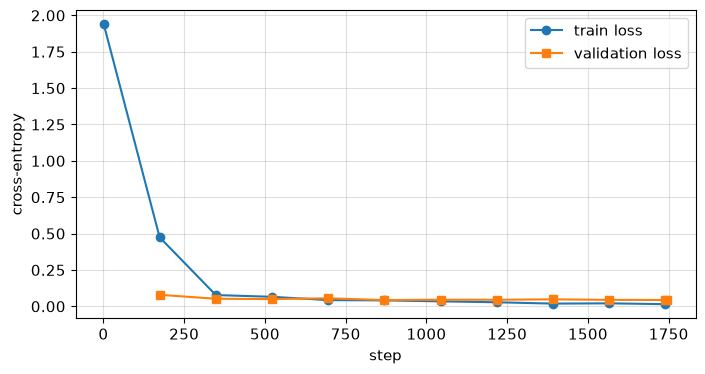

In [22]:
set_seed(SEED)
model = make_model()
history, train_seconds = train_ner(model, tokenized['train'], tokenized['validation'])
RUN_TIMES['train_main_sec'] = train_seconds
train_curve = [(h['step'], h['loss']) for h in history if 'loss' in h]
eval_curve = [(h['step'], h['eval_loss']) for h in history if 'eval_loss' in h]
assert len(train_curve) >= 2 and len(eval_curve) >= 2, 'логируйте train и eval loss по ходу обучения'
print(f'обучение: {train_seconds:.1f} c на {DEVICE_NAME}, {len(tokenized["train"])} предложений, {EPOCHS} эпох(а)')

best_step, best_loss = min(eval_curve, key=lambda point: point[1])
print(f'train loss: {train_curve[0][1]:.4f} → {train_curve[-1][1]:.4f}')
print(f'validation loss: {eval_curve[0][1]:.4f} → {eval_curve[-1][1]:.4f}, '
      f'минимум {best_loss:.4f} на шаге {best_step}')

plt.figure(figsize=(8, 4))
plt.plot(*zip(*train_curve), 'o-', label='train loss')
plt.plot(*zip(*eval_curve), 's-', label='validation loss')
plt.xlabel('step')
plt.ylabel('cross-entropy')
plt.legend()
plt.grid(True, alpha=0.4)
plt.show()

**Вопрос.** Почему выбраны такие гиперпараметры? Что видно на кривых: есть ли переобучение, нужно ли больше эпох? Сколько заняло обучение и на каком устройстве?

**Ответ:** Поставил learning rate `3e-5`, чтобы аккуратно дообучить предобученные веса RuBERT. Батч 16 - с запасом по памяти для T4, а на CUDA - FP16. На первые 105 шагов поднимаем learning rate, weight decay `0.01` сдерживает рост весов.
Для быстрого прогона беру одну эпоху, для полного - три. Если train loss продолжит падать, а validation loss начнёт устойчиво расти, это признак переобучения. В полном прогоне на RTX 3050 обучение с валидацией заняло 350 с. Train loss изменился с 1,9395 до 0,0149, а validation loss - с 0,0793 до 0,0435. Минимум validation loss 0,0429 получился на шаге 870. После минимума train loss в целом снижался, а validation loss колебался около достигнутого уровня.

## 4.2 Метрики (3 балла)

1. Посчитайте на validation и test отчет `seqeval` по типам (P/R/F1, support), micro и macro F1
2. Реализуйте `token_f1(gold, pred)` - micro-F1 по словам: верное срабатывание - слово, у которого предсказанный тег не `O` и совпадает с истинным; тег `O` в precision и recall не участвует; если не-`O` слов нет ни в gold, ни в pred, функция возвращает 0.0
3. Сравните токенный F1 и F1 по сущностям и объясните разницу

In [23]:
def token_f1(gold, pred):
    # gold, pred: списки списков BIO-тегов -> micro-F1 по словам без тега O
    true_positives = gold_count = pred_count = 0
    for gold_tags, pred_tags in zip(gold, pred, strict=True):
        for gold_tag, pred_tag in zip(gold_tags, pred_tags, strict=True):
            gold_count += gold_tag != 'O'
            pred_count += pred_tag != 'O'
            true_positives += gold_tag != 'O' and gold_tag == pred_tag

    denominator = gold_count + pred_count
    return 2 * true_positives / denominator if denominator else 0.0

In [24]:
g, p = [['B-PER', 'I-PER', 'O', 'B-LOC']], [['B-PER', 'O', 'O', 'B-LOC']]
assert abs(token_f1(g, p) - 0.8) < 1e-9                       # 2 верных слова из 2 предсказанных и 3 истинных
assert abs(f1_score(g, p) - 0.5) < 1e-9                       # а по сущностям верна одна из двух
assert token_f1([['O', 'O']], [['O', 'O']]) == 0.0 and token_f1(g, g) == 1.0

def evaluate_ner_split(split, gold, pred):
    report = classification_report(gold, pred, digits=4, output_dict=True, zero_division=0)
    micro = report['micro avg']
    empty_type = {'precision': 0.0, 'recall': 0.0, 'f1-score': 0.0, 'support': 0}
    per_type = {kind: report.get(kind, empty_type.copy()) for kind in ENTITY_TYPES}
    scores = dict(
        f1_micro=micro['f1-score'],
        f1_macro=report['macro avg']['f1-score'],
        precision=micro['precision'],
        recall=micro['recall'],
        token_f1=token_f1(gold, pred),
        per_type=per_type,
    )

    print(f'\n{split}: метрики по сущностям')
    print(f'{"Тип":<12}{"Precision":>10}{"Recall":>10}{"F1":>10}{"Support":>10}')
    for kind in (*ENTITY_TYPES, 'micro avg', 'macro avg'):
        row = report[kind] if kind in report else per_type[kind]
        print(f'{kind:<12}{row["precision"]:>10.4f}{row["recall"]:>10.4f}'
              f'{row["f1-score"]:>10.4f}{row["support"]:>10}')

    print(f'F1 по словам: {scores["token_f1"]:.4f}')
    print(f'F1 по словам минус micro F1 по сущностям: {scores["token_f1"] - scores["f1_micro"]:+.4f}')
    supported_types = {kind: row['f1-score'] for kind, row in per_type.items() if row['support']}
    if supported_types:
        worst_f1 = min(supported_types.values())
        weakest = ', '.join(kind for kind, value in supported_types.items() if value == worst_f1)
        print(f'Ниже всего F1 среди типов, которые есть в разметке: {weakest} ({worst_f1:.4f})')
    return scores


val_pred = predict_word_tags(model, val_tokens, batch_size=BATCH_SIZE)
validation_scores = evaluate_ner_split('validation', val_gold, val_pred)

test_tokens = [list(words) for words in data['test']['tokens']]
test_gold = [[LABEL_NAMES[tag_id] for tag_id in tags] for tags in data['test']['ner_tags']]
test_pred = predict_word_tags(model, test_tokens, batch_size=BATCH_SIZE)
final = evaluate_ner_split('test', test_gold, test_pred)


validation: метрики по сущностям
Тип          Precision    Recall        F1   Support
LOC             0.9548    0.9769    0.9657      1168
ORG             0.8662    0.9006    0.8831      1308
PER             0.9842    0.9878    0.9860      1641
micro avg       0.9376    0.9570    0.9472      4117
macro avg       0.9351    0.9551    0.9449      4117
F1 по словам: 0.9552
F1 по словам минус micro F1 по сущностям: +0.0080
Ниже всего F1 среди типов, которые есть в разметке: ORG (0.8831)

test: метрики по сущностям
Тип          Precision    Recall        F1   Support
LOC             0.9695    0.9728    0.9711      1175
ORG             0.8667    0.9061    0.8859      1256
PER             0.9910    0.9847    0.9879      1570
micro avg       0.9445    0.9565    0.9505      4001
macro avg       0.9424    0.9545    0.9483      4001
F1 по словам: 0.9555
F1 по словам минус micro F1 по сущностям: +0.0051
Ниже всего F1 среди типов, которые есть в разметке: ORG (0.8859)


**Вопрос.** Какой тип сущностей распознается хуже всего и почему (частота, длина спанов, разнообразие)? Чем отличаются micro и macro F1 в вашем случае? Чем отличаются токенный F1 и F1 по сущностям в ваших числах и за счет чего (какой выше и почему)? Какой из них ближе к тому, что нужно пользователю NER?

**Ответ:** Самый слабый тип и на validation и на test - ORG (F1 0,8831 и 0,8859). F1 по словам и по сущностям соответственно составили 0,9552 и 0,9472 на validation, 0,9555 и 0,9505 на test. Частота в train, длина и разнообразие названий могут объяснить низкий F1, но по одной таблице метрик причину не видно. Micro F1 считает все упоминания вместе, поэтому частые типы сильнее влияют на итог, а macro даёт каждому типу одинаковый вес.
Токенный F1 засчитывает правильно размеченные слова внутри сущности. Например, если поставили правильный тег на «Имя», но пропустили «Фамилия», одно слово засчитается, а спан «Имя Фамилия» - нет. Пользователю NER ближе F1 по сущностям, потому что важны полное название и его тип.

---
# 5. Анализ

## 5.1 Разбор ошибок (2 балла)

Аналог разбора ошибок детектора по IoU. Реализуйте `categorize_errors(gold_spans, pred_spans)`: каждый истинный спан получает ровно одну категорию, предсказанный спан, не пересекающийся ни с одним истинным, - категорию `spurious`. Возвращается список `(категория, истинный спан или None, предсказанный спан или None)`:

- `correct` - есть предсказанный спан с теми же границами и типом
- `boundary` - точного совпадения нет, но есть пересекающийся предсказанный спан того же типа (ошибка границы, аналог ошибки локализации)
- `type` - пересекающегося спана того же типа нет, но есть пересекающийся спан другого типа (ошибка типа, аналог ошибки класса)
- `missed` - ни один предсказанный спан не пересекается с истинным (пропуск)
- `spurious` - лишний спан (ложное срабатывание)

Посчитайте категории на validation, доли среди ошибок, покажите 5+ примеров ошибок разных категорий глазами (предложение, истинный и предсказанный спаны).

In [25]:
ERROR_CATEGORIES = ['correct', 'boundary', 'type', 'missed', 'spurious']


def categorize_errors(gold_spans, pred_spans):
    # -> [(категория, gold-спан или None, pred-спан или None), ...]
    def overlap_size(a, b):
        return max(0, min(a[1], b[1]) - max(a[0], b[0]))

    results = []
    for gold in gold_spans:
        if gold in pred_spans:
            results.append(('correct', gold, gold))
            continue

        overlapping = [pred for pred in pred_spans if overlap_size(gold, pred)]
        if not overlapping:
            results.append(('missed', gold, None))
            continue

        same_type = [pred for pred in overlapping if pred[2] == gold[2]]
        category = 'boundary' if same_type else 'type'
        best = max(same_type or overlapping, key=lambda pred: overlap_size(gold, pred))
        results.append((category, gold, best))

    for pred in pred_spans:
        if not any(overlap_size(gold, pred) for gold in gold_spans):
            results.append(('spurious', None, pred))
    return results

In [26]:
gold = [(0, 2, 'PER'), (4, 5, 'LOC'), (7, 9, 'ORG'), (11, 12, 'PER')]
pred = [(0, 2, 'PER'), (4, 6, 'LOC'), (7, 9, 'LOC'), (13, 14, 'ORG')]
res = categorize_errors(gold, pred)
assert collections.Counter(c for c, _, _ in res) == {'correct': 1, 'boundary': 1, 'type': 1, 'missed': 1, 'spurious': 1}
assert ('type', (7, 9, 'ORG'), (7, 9, 'LOC')) in res and ('spurious', None, (13, 14, 'ORG')) in res
assert ('boundary', (4, 5, 'LOC'), (4, 6, 'LOC')) in res and ('missed', (11, 12, 'PER'), None) in res
assert categorize_errors([], []) == [] and categorize_errors([], [(0, 1, 'PER')]) == [('spurious', None, (0, 1, 'PER'))]
assert [c for c, _, _ in categorize_errors([(0, 3, 'LOC')], [(1, 2, 'PER'), (2, 3, 'LOC')])] == ['boundary']
assert [c for c, _, _ in categorize_errors([(0, 2, 'LOC'), (2, 4, 'LOC')], [(0, 4, 'LOC')])] == ['boundary', 'boundary']
assert sorted(c for c, _, _ in categorize_errors([(0, 2, 'PER')], [(2, 3, 'PER')])) == ['missed', 'spurious']   # end не включается: спаны только соприкасаются

counts = collections.Counter()
error_examples = collections.defaultdict(list)
for words, gold_tags, pred_tags in zip(val_tokens, val_gold, val_pred, strict=True):
    for category, gold_span, pred_span in categorize_errors(bio_to_spans(gold_tags), bio_to_spans(pred_tags)):
        counts[category] += 1
        if category != 'correct' and len(error_examples[category]) < 2:
            error_examples[category].append((words, gold_span, pred_span))

errors = {category: counts[category] for category in ERROR_CATEGORIES}
n_errors = sum(count for category, count in errors.items() if category != 'correct')
print(f'Правильные спаны: {errors["correct"]}. Ошибки: {n_errors}.')
for category in ERROR_CATEGORIES[1:]:
    share = errors[category] / n_errors if n_errors else 0
    print(f'{category:<9} {errors[category]:>4} ({share:.1%} ошибок)')


def describe_span(words, span):
    if span is None:
        return '∅'
    start, end, kind = span
    return f'{kind} [{start}:{end}] «{" ".join(words[start:end])}»'


for category in ERROR_CATEGORIES[1:]:
    for words, gold_span, pred_span in error_examples[category]:
        print(f'\n[{category}] {" ".join(words)}')
        print(f'Истинный спан: {describe_span(words, gold_span)}')
        print(f'Предсказание: {describe_span(words, pred_span)}')

Правильные спаны: 3940. Ошибки: 299.
boundary    89 (29.8% ошибок)
type        23 (7.7% ошибок)
missed      65 (21.7% ошибок)
spurious   122 (40.8% ошибок)

[boundary] Акционеры издательского дома ( ИД ) " Коммерсантъ " согласились на отставку гендиректора Демьяна Кудрявцева .
Истинный спан: ORG [4:5] «ИД»
Предсказание: ORG [1:6] «издательского дома ( ИД )»

[boundary] Издательский дом " Коммерсантъ " создан в 1988г . В 2006г . его владельцем стал бизнесмен А . Усманов .
Истинный спан: ORG [0:4] «Издательский дом " Коммерсантъ»
Предсказание: ORG [0:2] «Издательский дом»

[type] Во внешнеполитическом ведомстве США Басс также занимался отношениями России и НАТО , а также принимал участие в переговорах о сокращении обычных вооружений в Европе .
Истинный спан: PER [4:5] «Басс»
Предсказание: ORG [4:5] «Басс»

[type] Госкорпорация пока генерирует убыток по МСФО .
Истинный спан: LOC [5:6] «МСФО»
Предсказание: ORG [5:6] «МСФО»

[missed] Представители компании связывали снижение чистой прибыли 

**Вопрос.** Какая категория ошибок самая частая? Что общего у примеров в каждой категории? Какие ошибки - на самом деле ошибки разметки, а не модели? Что бы вы сделали, чтобы уменьшить самую частую категорию?

**Ответ:** Самая частая ошибка - `spurious`, 122 из 299 (40,8%). В примерах модель выделяет «издательского дома ( ИД )» вместо «ИД» и «Издательский дом» вместо «Издательский дом " Коммерсантъ». При ошибке типа «Басс» получили метку ORG вместо PER. Среди пропусков есть «Intel», а среди лишних спанов - «областной». В выражении «убыток по МСФО» речь о стандартах финансовой отчётности. Чтобы уменьшить число лишних спанов, я бы добавил примеры, где общие слова вроде «областной» и «войск» стоят рядом с названиями и сами получают тег `O`.

## 5.2 Абляция (1 балл)

Один дополнительный эксперимент на выбор, все остальное как в 4.1:

- `'freeze'` - замороженный энкодер (учится только голова) vs полное дообучение. Сравните F1, время и число обучаемых параметров
- `'all_subwords'` - метка на все сабворды (`data.map(tokenize_and_align, batched=True, remove_columns=data['train'].column_names, fn_kwargs=dict(label_all_subwords=True))`) vs только на первый. Оценка по-прежнему по словам через `predict_word_tags`

Результат положите в `ablation` - словарь с настройкой и метриками обоих вариантов.

In [27]:
ABLATION = 'freeze'   # 'freeze' или 'all_subwords'
assert ABLATION in {'freeze', 'all_subwords'}
ablation_data = tokenized
if ABLATION == 'all_subwords':
    ablation_data = data.map(
        tokenize_and_align,
        batched=True,
        remove_columns=data['train'].column_names,
        fn_kwargs={'label_all_subwords': True},
    )

# Повторяем инициализацию из 4.1 и меняем ровно одну настройку обучения.
baseline_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
model.cpu()
set_seed(SEED)
ablation_model = make_model()
_, ablation_seconds = train_ner(
    ablation_model, ablation_data['train'], ablation_data['validation'],
    freeze_encoder=ABLATION == 'freeze', out_dir=f'runs/ablation-{ABLATION}',
)
ablation_pred = predict_word_tags(ablation_model, val_tokens, batch_size=BATCH_SIZE)
ablation_params = sum(p.numel() for p in ablation_model.parameters() if p.requires_grad)
del ablation_model

ablation = {
    'setting': ABLATION,
    'split': 'validation',
    'baseline': dict(entity_scores(val_gold, val_pred), seconds=train_seconds, trainable_params=baseline_params),
    'variant': dict(entity_scores(val_gold, ablation_pred), seconds=ablation_seconds, trainable_params=ablation_params),
}
delta_f1 = ablation['variant']['f1_micro'] - ablation['baseline']['f1_micro']
for name in ('baseline', 'variant'):
    row = ablation[name]
    print(f'{name:<8} micro-F1 {row["f1_micro"]:.4f}, macro-F1 {row["f1_macro"]:.4f}, '
          f'{row["seconds"]:.1f} с, обучаемых параметров: {row["trainable_params"]:,}')
print(f'Разница micro-F1: {delta_f1:+.4f}. Отношение времени base/variant: {train_seconds / ablation_seconds:.2f}×.')

{'loss': '1.939', 'grad_norm': 'inf', 'learning_rate': '0', 'epoch': '0.001718'}
{'loss': '1.719', 'grad_norm': '4.165', 'learning_rate': '2.876e-05', 'epoch': '0.299'}
{'eval_loss': '1.382', 'eval_runtime': '3.415', 'eval_samples_per_second': '630.4', 'eval_steps_per_second': '39.53', 'epoch': '0.299'}
{'loss': '1.139', 'grad_norm': '2.53', 'learning_rate': '2.558e-05', 'epoch': '0.5979'}
{'eval_loss': '0.8939', 'eval_runtime': '3.471', 'eval_samples_per_second': '620.4', 'eval_steps_per_second': '38.9', 'epoch': '0.5979'}
{'loss': '0.8102', 'grad_norm': '1.41', 'learning_rate': '2.239e-05', 'epoch': '0.8969'}
{'eval_loss': '0.6669', 'eval_runtime': '3.435', 'eval_samples_per_second': '626.7', 'eval_steps_per_second': '39.3', 'epoch': '0.8969'}
{'loss': '0.6473', 'grad_norm': '0.8771', 'learning_rate': '1.921e-05', 'epoch': '1.196'}
{'eval_loss': '0.5654', 'eval_runtime': '3.442', 'eval_samples_per_second': '625.5', 'eval_steps_per_second': '39.22', 'epoch': '1.196'}
{'loss': '0.5791'

**Вопрос.** Насколько изменилась метрика и время? Чем вы объясняете результат? Что бы вы проверили следующим шагом, чтобы вывод был надежнее?

**Ответ:** На одной и той же validation micro-F1 изменился с 0,9472 до 0,1511. Время обучения вместе с промежуточной валидацией изменилось с 350,2 до 95,8 с, а число обучаемых параметров — с 177 722 119 до 5 383. При заморозке меняются только веса головы, поэтому энкодер не адаптируется к границам и типам сущностей. Для надёжного сравнения я бы повторил эксперимент с несколькими разными seed и сравнил разброс F1.

## 5.3 Выводы (1 балл)

5-8 предложений с числами: что сработало, что нет, главные ограничения (данные, разметка, модель, бюджет), что бы вы сделали дальше.

**Ответ:** За три эпохи на полном train из 9301 предложений RuBERT получил micro-F1 0,9472 на validation против 0,5613 у словарного бейзлайна и 0,0261 у случайной головы. На 1922 тестовых предложениях F1 по сущностям составил 0,9505, а F1 по словам - 0,9555. На validation лучше всего распознавался тип PER (0,9860), слабее всего - ORG (0,8831). Неверные границы дали 89 из 299 ошибок, лишние спаны - 122. При заморозке энкодера на той же validation получилось 0,1511. Этот прогон выполнен с одним seed, а лимит 128 сабвордов может скрывать хвосты длинных предложений. Дальше я бы добавил примеры составных ORG и проверил разброс качества с несколькими seed.

### Сохранение результатов

Ячейка сохраняет `artifacts/metrics.json`. Выполняется и в `FAST_MODE` для проверки формата, при финальном прогоне перезаписывается с `fast_mode: false`. Сдайте файл вместе с ноутбуком.

In [28]:
def json_ready(value):
    if isinstance(value, torch.Tensor):
        return json_ready(value.detach().cpu().tolist())
    if isinstance(value, np.ndarray):
        return json_ready(value.tolist())
    if isinstance(value, dict):
        return {str(k): json_ready(v) for k, v in value.items()}
    if isinstance(value, (tuple, list)):
        return [json_ready(v) for v in value]
    if isinstance(value, (float, np.floating)):
        return float(value) if math.isfinite(value) else None
    if isinstance(value, np.integer):
        return int(value)
    if isinstance(value, Path):
        return value.as_posix()
    return value


metrics = dict(
    track='nlp', model=MODEL_ID, revision=REVISION,
    dataset=f'{DATASET_ID}/{DATASET_CONFIG}' if DATASET_CONFIG else str(DATASET_ID), classes=ENTITY_TYPES,
    n_train=len(data['train']), n_val=len(data['validation']), n_test=len(data['test']),
    params_total=sum(p.numel() for p in model.parameters()),
    baseline=baseline, final=final, ablation=ablation, errors=errors,
    device=DEVICE_NAME, train_time_sec=RUN_TIMES.get('train_main_sec'), fast_mode=FAST_MODE)
for key in ['f1_micro', 'f1_macro', 'precision', 'recall', 'token_f1', 'per_type']:
    assert key in final, f'в final нет {key}'
(ARTIFACTS / 'metrics.json').write_text(json.dumps(json_ready(metrics), ensure_ascii=False, indent=2), encoding='utf-8')
print(json.dumps(json_ready({k: v for k, v in metrics.items() if k not in ('final', 'baseline')}), ensure_ascii=False)[:600])
print('final F1 micro', round(final['f1_micro'], 4))

{"track": "nlp", "model": "ai-forever/ruBert-base", "revision": "05f37a2ca9e333fd18f30cd0c96c68d274793c69", "dataset": "RCC-MSU/collection3", "classes": ["LOC", "ORG", "PER"], "n_train": 9301, "n_val": 2153, "n_test": 1922, "params_total": 177722119, "ablation": {"setting": "freeze", "split": "validation", "baseline": {"f1_micro": 0.9472292342829667, "f1_macro": 0.9449299145131475, "precision": 0.9376487386958591, "recall": 0.9570075297546757, "seconds": 350.165285199997, "trainable_params": 177722119}, "variant": {"f1_micro": 0.1510654490106545, "f1_macro": 0.1078692788101329, "precision": 0.
final F1 micro 0.9505


---
# 6\*. Бонусные задачи

Включаются через `BONUS_TASKS`, за бонусы суммарно - до 4 баллов из 5.5 предложенных.

## 6.1 Доразметка (1.5 балла)

Разметьте сами 50+ новых предложений (Label Studio, doccano или вручную в JSON): например, тексты из другого источника или трудные случаи из 5.1. Опишите инструкцию разметки, приведите разметку к контракту из 2.1, добавьте в train (или сделайте отдельный test) и покажите, как изменилась метрика. Файл с разметкой приложите к сдаче.

In [29]:
if '6.1' in BONUS_TASKS:
    annotation_path = Path('annotations_6_1.jsonl')
    with annotation_path.open(encoding='utf-8') as stream:
        annotations = [json.loads(line) for line in stream if line.strip()]

    assert len(annotations) >= 50
    assert len({row['id'] for row in annotations}) == len(annotations)
    assert len({tuple(row['tokens']) for row in annotations}) == len(annotations)
    corpus_tokens = {tuple(words) for split in raw.values() for words in split['tokens']}
    extra_rows = []
    for row in annotations:
        assert row['tokens'] and tuple(row['tokens']) not in corpus_tokens
        assert all(span[2] in ENTITY_TYPES for span in row['spans'])
        tags = spans_to_bio(row['spans'], len(row['tokens']))
        assert bio_to_spans(tags) == [tuple(span) for span in row['spans']]
        extra_rows.append({'id': row['id'], 'tokens': row['tokens'], 'ner_tags': [label2id[tag] for tag in tags]})

    extra_test = datasets.Dataset.from_list(extra_rows)
    extra_gold = [[LABEL_NAMES[i] for i in ids] for ids in extra_test['ner_tags']]
    extra_pred = predict_word_tags(model, extra_test['tokens'], batch_size=BATCH_SIZE)
    print(f'Новый тест: {len(extra_test)} предложений. Группы: {dict(collections.Counter(row["group"] for row in annotations))}')
    extra_scores = evaluate_ner_split('6.1, новый тест', extra_gold, extra_pred)
    print(f'Исходный test Collection3: micro-F1 {final["f1_micro"]:.4f}. '
          f'Разница на новом тесте: {extra_scores["f1_micro"] - final["f1_micro"]:+.4f}.')
    extra_group_scores = {}
    for group in ('news', 'messages', 'difficult'):
        indices = [i for i, row in enumerate(annotations) if row['group'] == group]
        group_scores = entity_scores([extra_gold[i] for i in indices], [extra_pred[i] for i in indices])
        extra_group_scores[group] = group_scores
        print(f'{group}: {len(indices)} предложений, micro-F1 {group_scores["f1_micro"]:.4f}')

    bonus_results['6.1'] = dict(scores=extra_scores, n_sentences=len(extra_test), groups=extra_group_scores)

Новый тест: 54 предложений. Группы: {'news': 18, 'messages': 18, 'difficult': 18}

6.1, новый тест: метрики по сущностям
Тип          Precision    Recall        F1   Support
LOC             0.7209    0.9688    0.8267        32
ORG             0.6061    0.5714    0.5882        35
PER             0.9643    0.9643    0.9643        28
micro avg       0.7500    0.8211    0.7839        95
macro avg       0.7638    0.8348    0.7931        95
F1 по словам: 0.8849
F1 по словам минус micro F1 по сущностям: +0.1010
Ниже всего F1 среди типов, которые есть в разметке: ORG (0.5882)
Исходный test Collection3: micro-F1 0.9505. Разница на новом тесте: -0.1665.
news: 18 предложений, micro-F1 0.8205
messages: 18 предложений, micro-F1 0.8929
difficult: 18 предложений, micro-F1 0.6462


**Вопрос.** Сколько и каких примеров вы разметили, сколько времени заняла разметка, как изменилась метрика и на каком сплите? Где вы сами сомневались в разметке?

**Ответ:** С помощью LLM) разметили 54 синтетических предложения - по 18 новостей, бытовых сообщений и трудных примеров. Всего получилось 95 сущностей (28 `PER`, 32 `LOC`, 35 `ORG`).

Имена людей размечали как `PER`, географические названия - как `LOC`, полные названия организаций — как `ORG`. Спорный случай - имя человека внутри названия учреждения. В таких случаях всё название размечали одним спаном `ORG`.

На отдельном тесте из 54 предложений micro-F1 по сущностям составил 0,7839 против 0,9505 на тесте Collection3 (−16,65 п.п.). Самый низкий результат был на трудных примерах — 0,6462. Сильнее всего упал F1 для организаций — с 0,8859 до 0,5882. Например, модель разбила «Союз архитекторов России» на «Союз архитекторов» (`ORG`) и «России» (`LOC`), хотя в разметке это одна организация. Метрика засчитала одну пропущенную и две лишние сущности.

## 6.2 Другая модель (1 балл)

Сравните с другим энкодером (многоязычный vs одноязычный, base vs маленький) при том же протоколе - или zero-shot NER открытой LLM с Hugging Face против дообученного энкодера. Сравните F1, время обучения и инференса, размер.

In [30]:
if '6.2' in BONUS_TASKS:
    tiny_id = 'cointegrated/rubert-tiny2'
    tiny_revision = 'e8ed3b0c8bbf4fb6984c3de043bf7d2f4e5969ae'
    tiny_tokenizer = AutoTokenizer.from_pretrained(tiny_id, revision=tiny_revision)
    assert tiny_tokenizer.is_fast
    tiny_data = data.map(
        tokenize_and_align, batched=True, remove_columns=data['train'].column_names,
        fn_kwargs={'tok': tiny_tokenizer},
    )
    set_seed(SEED)
    tiny_model = make_model(tiny_id, tiny_revision)
    _, tiny_train_seconds = train_ner(
        tiny_model, tiny_data['train'], tiny_data['validation'],
        tok=tiny_tokenizer, out_dir='runs/rubert-tiny2',
    )
    timing_words = val_tokens[:BATCH_SIZE]
    model_comparison = {}
    for name, ner_model, tok, seconds, val_scores, test_scores in (
        (MODEL_ID, model, tokenizer, train_seconds, validation_scores, final),
        (tiny_id, tiny_model, tiny_tokenizer, tiny_train_seconds, None, None),
    ):
        if val_scores is None:
            tiny_val_pred = predict_word_tags(ner_model, val_tokens, tok=tok, batch_size=BATCH_SIZE)
            tiny_test_pred = predict_word_tags(ner_model, test_tokens, tok=tok, batch_size=BATCH_SIZE)
            val_scores = entity_scores(val_gold, tiny_val_pred)
            test_scores = entity_scores(test_gold, tiny_test_pred)

        for _ in range(3):
            predict_word_tags(ner_model, timing_words, tok=tok, batch_size=BATCH_SIZE)
        started = time.perf_counter()
        for _ in range(12):
            predict_word_tags(ner_model, timing_words, tok=tok, batch_size=BATCH_SIZE)
        inference_ms = (time.perf_counter() - started) * 1000 / 12

        model_comparison[name] = dict(
            validation={key: val_scores[key] for key in ('f1_micro', 'f1_macro')},
            test={key: test_scores[key] for key in ('f1_micro', 'f1_macro')},
            train_seconds=seconds, inference_ms=inference_ms,
            params=sum(p.numel() for p in ner_model.parameters()),
            parameter_mib=sum(p.numel() * p.element_size() for p in ner_model.parameters()) / 2**20,
        )

    print(f'{DEVICE_NAME}, {EPOCHS} эпох(а), инференс на батче из {len(timing_words)} предложений')
    print('Модель | validation micro / macro | test micro / macro | обучение | инференс | параметры')
    for name, row in model_comparison.items():
        val, test = row['validation'], row['test']
        print(f'{name} | {val["f1_micro"]:.4f} / {val["f1_macro"]:.4f} | '
              f'{test["f1_micro"]:.4f} / {test["f1_macro"]:.4f} | {row["train_seconds"]:.1f} с | '
              f'{row["inference_ms"]:.1f} мс | {row["params"]:,} ({row["parameter_mib"]:.1f} МиБ)')
    bonus_results['6.2'] = dict(models=model_comparison, tiny_revision=tiny_revision, device=DEVICE_NAME,
                                batch_size=len(timing_words), repeats=12)
    del tiny_model, ner_model

{'loss': '1.813', 'grad_norm': '8.401', 'learning_rate': '0', 'epoch': '0.001718'}
{'loss': '0.8509', 'grad_norm': '2.952', 'learning_rate': '2.876e-05', 'epoch': '0.299'}
{'eval_loss': '0.2507', 'eval_runtime': '1.09', 'eval_samples_per_second': '1975', 'eval_steps_per_second': '123.8', 'epoch': '0.299'}
{'loss': '0.218', 'grad_norm': '1.18', 'learning_rate': '2.558e-05', 'epoch': '0.5979'}
{'eval_loss': '0.1284', 'eval_runtime': '0.9631', 'eval_samples_per_second': '2236', 'eval_steps_per_second': '140.2', 'epoch': '0.5979'}
{'loss': '0.1426', 'grad_norm': '1.653', 'learning_rate': '2.239e-05', 'epoch': '0.8969'}
{'eval_loss': '0.09695', 'eval_runtime': '1.003', 'eval_samples_per_second': '2147', 'eval_steps_per_second': '134.7', 'epoch': '0.8969'}
{'loss': '0.09917', 'grad_norm': '1.721', 'learning_rate': '1.921e-05', 'epoch': '1.196'}
{'eval_loss': '0.07435', 'eval_runtime': '0.9868', 'eval_samples_per_second': '2182', 'eval_steps_per_second': '136.8', 'epoch': '1.196'}
{'loss': '0

**Вопрос.** Что лучше и какой ценой (время, память)? Как вы обеспечили честность сравнения?

**Ответ.** На тесте RuBERT-base получил micro-F1 0,9505, а RuBERT-tiny2 - 0,8979. Разница составила 5,3 п.п. При этом у tiny2 в 6,1 раза меньше параметров (111 против 678 МиБ весов). На RTX 3050 обучение заняло 73,6 с против 350,2 с в 4.1, а обработка того же батча из 16 предложений - 14,2 мс против 30,8 мс. Обе модели обучались на тех же примерах с одинаковыми настройками, включая seed, число эпох и LR. Каждая использовала свой токенизатор, а F1 посчитали по тем же границам сущностей на уровне слов. Разница в F1 относится к этому общему бюджету обучения.

## 6.3 Устойчивость к сдвигу (1 балл)

Испортите validation и посмотрите на F1: опечатки, весь текст в нижнем или верхнем регистре, транслит, или другой домен (новости, соцсети, другой датасет с теми же типами). Метки при порче не меняются.

In [31]:
if '6.3' in BONUS_TASKS:
    # Одна опечатка: меняем местами разные соседние буквы внутри слова.
    def transpose_words(sentences, rate, seed):
        rng = random.Random(seed)
        typo_sentences = [words.copy() for words in sentences]
        eligible = [
            (i, j, swaps)
            for i, words in enumerate(sentences)
            for j, word in enumerate(words)
            if len(word) >= 4 and word.isalpha()
            and (swaps := [k for k, (a, b) in enumerate(zip(word, word[1:])) if a != b])
        ]
        for i, j, swaps in rng.sample(eligible, round(len(eligible) * rate)):
            word = sentences[i][j]
            k = rng.choice(swaps)
            typo_sentences[i][j] = word[:k] + word[k + 1] + word[k] + word[k + 2:]
        return typo_sentences

    cyrillic = 'абвгдеёжзийклмнопрстуфхцчшщъыьэюя'
    latin = ('a b v g d e yo zh z i y k l m n o p r s t u f kh ts ch sh shch ” y ’ e yu ya').split()
    transliteration = dict(zip(cyrillic, latin, strict=True))
    transliteration.update({letter.upper(): value.capitalize() for letter, value in transliteration.items()})
    translit_table = str.maketrans(transliteration)
    shifted_inputs = {
        'lowercase': [[word.lower() for word in words] for words in val_tokens],
        'uppercase': [[word.upper() for word in words] for words in val_tokens],
        'typo': transpose_words(val_tokens, rate=0.15, seed=SEED),
        'translit': [[word.translate(translit_table) for word in words] for words in val_tokens],
    }
    clean_score = entity_scores(val_gold, val_pred)
    clean_ids = tokenizer(val_tokens, is_split_into_words=True, truncation=True, max_length=MAX_LENGTH)['input_ids']
    word_count = sum(map(len, val_tokens))
    shifted_scores = {'clean': dict(clean_score, delta_f1=0.0, changed_words=0, changed_tokenizations=0)}
    for name, sentences in shifted_inputs.items():
        changed = sum(a != b for old, new in zip(val_tokens, sentences, strict=True)
                      for a, b in zip(old, new, strict=True))
        ids = tokenizer(sentences, is_split_into_words=True, truncation=True, max_length=MAX_LENGTH)['input_ids']
        pred = predict_word_tags(model, sentences, batch_size=BATCH_SIZE)
        scores = entity_scores(val_gold, pred)
        shifted_scores[name] = dict(
            scores, delta_f1=scores['f1_micro'] - clean_score['f1_micro'], changed_words=changed,
            changed_tokenizations=sum(before != after for before, after in zip(clean_ids, ids, strict=True)),
        )

    print('Вариант | micro-F1 | ΔF1, п.п. | изменено слов | вход изменился в предложениях')
    for name, row in shifted_scores.items():
        print(f'{name:<10} {row["f1_micro"]:.4f} | {100 * row["delta_f1"]:+.2f} | '
              f'{row["changed_words"]}/{word_count} | {row["changed_tokenizations"]}/{len(val_tokens)}')
    for word in ('Москва', 'москва', 'МОСКВА', 'Мосвка', 'Moskva'):
        print(f'{word}: {tokenizer.tokenize(word)}')
    bonus_results['6.3'] = dict(variants=shifted_scores, split='validation', word_count=word_count,
                                typo_rate_among_eligible=0.15)

Вариант | micro-F1 | ΔF1, п.п. | изменено слов | вход изменился в предложениях
clean      0.9472 | +0.00 | 0/43856 | 0/2153
lowercase  0.9472 | +0.00 | 8033/43856 | 0/2153
uppercase  0.9472 | +0.00 | 33997/43856 | 0/2153
typo       0.8886 | -5.86 | 3994/43856 | 1694/2153
translit   0.0742 | -87.30 | 34951/43856 | 2145/2153
Москва: ['моск', '##ва']
москва: ['моск', '##ва']
МОСКВА: ['моск', '##ва']
Мосвка: ['мо', '##с', '##вка']
Moskva: ['mos', '##k', '##va']


**Вопрос.** Какая порча сильнее всего роняет F1 и почему (вспомните, как токенизатор режет слова и какие признаки сущности есть в тексте)?

**Ответ.** Самым сильным искажением оказался транслит. Micro-F1 упал с 0,9472 до 0,0742. На предложениях с опечатками получилось 0,8886, при нижнем регистре - 0,9472, при верхнем - 0,9472. Токенизатор приводит текст к нижнему регистру, поэтому `Москва`, `москва` и `МОСКВА` дают одинаковые `моск`, `##ва`. Опечатка `Мосвка` меняет разбиение на `мо`, `##с`, `##вка`, а `Moskva` целиком переходит на латинские сабворды. При транслите меняются и сами названия, и слова вокруг, по которым модель распознаёт сущности. Транслит применялся ко всей кириллице, а опечатки внесены в 15% подходящих слов.

## 6.4 Экспорт и скорость (1 балл)

Экспортируйте модель в ONNX (или примените `torch.compile` / квантизацию), замерьте задержку до и после на одном и том же батче и устройстве (с прогревом, среднее по 10+ запускам) и проверьте, что F1 не упал (или упал незначительно).

Для ONNX: `%pip install -q onnx onnxruntime onnxscript`.

In [32]:
if '6.4' in BONUS_TASKS:
    from tempfile import TemporaryDirectory
    from types import SimpleNamespace

    import onnxruntime as ort

    class LogitsOnly(torch.nn.Module):
        def __init__(self, ner_model):
            super().__init__()
            self.ner_model = ner_model

        def forward(self, input_ids, attention_mask, token_type_ids):
            return self.ner_model(
                input_ids=input_ids, attention_mask=attention_mask, token_type_ids=token_type_ids,
            ).logits

    class RuntimeNER(torch.nn.Module):
        def __init__(self, session, config):
            super().__init__()
            self.session = session
            self.config = config

        def forward(self, **inputs):
            batch = {name: value.numpy() for name, value in inputs.items()}
            logits, = self.session.run(['logits'], batch)
            return SimpleNamespace(logits=torch.from_numpy(logits))

    def mean_forward_ms(forward, repeats=12):
        for _ in range(3):
            forward()
        started = time.perf_counter()
        for _ in range(repeats):
            forward()
        return (time.perf_counter() - started) * 1000 / repeats

    cpu = torch.device('cpu')
    original_device = next(model.parameters()).device
    input_names = ('input_ids', 'attention_mask', 'token_type_ids')
    encoded = tokenizer(
        val_tokens[:BATCH_SIZE], is_split_into_words=True, padding=True,
        truncation=True, max_length=MAX_LENGTH, return_tensors='pt',
    )
    cpu_inputs = tuple(encoded[name] for name in input_names)
    runtime_inputs = {name: tensor.numpy() for name, tensor in zip(input_names, cpu_inputs, strict=True)}
    export_model = LogitsOnly(model.to(cpu)).eval()
    try:
        with TemporaryDirectory(prefix='ner-onnx-') as tmp:
            onnx_path = Path(tmp) / 'rubert-ner.onnx'
            with torch.no_grad():
                torch.onnx.export(
                    export_model, cpu_inputs, str(onnx_path), opset_version=17, dynamo=False,
                    input_names=list(input_names), output_names=['logits'],
                    dynamic_axes={name: {0: 'batch', 1: 'sequence'} for name in (*input_names, 'logits')},
                )
            options = ort.SessionOptions()
            options.intra_op_num_threads = torch.get_num_threads()
            session = ort.InferenceSession(str(onnx_path), sess_options=options, providers=['CPUExecutionProvider'])
            with torch.inference_mode():
                eager_logits = export_model(*cpu_inputs).numpy()
                ort_logits, = session.run(['logits'], runtime_inputs)
                np.testing.assert_allclose(eager_logits, ort_logits, rtol=1e-3, atol=1e-3)
                eager_ms = mean_forward_ms(lambda: export_model(*cpu_inputs))
                ort_ms = mean_forward_ms(lambda: session.run(['logits'], runtime_inputs))

            cpu_pred = predict_word_tags(model, val_tokens, batch_size=BATCH_SIZE, dev=cpu)
            runtime_model = RuntimeNER(session, model.config)
            ort_pred = predict_word_tags(runtime_model, val_tokens, batch_size=BATCH_SIZE, dev=cpu)
            eager_scores = entity_scores(val_gold, cpu_pred)
            ort_scores = entity_scores(val_gold, ort_pred)
            changed_tags = sum(a != b for old, new in zip(cpu_pred, ort_pred, strict=True)
                               for a, b in zip(old, new, strict=True))
            export_size = sum(p.stat().st_size for p in Path(tmp).iterdir() if p.is_file()) / 2**20
            del runtime_model, session
    finally:
        model.to(original_device)

    latency_ratio = eager_ms / ort_ms
    f1_delta = ort_scores['f1_micro'] - eager_scores['f1_micro']
    max_logit_delta = float(np.max(np.abs(eager_logits - ort_logits)))
    print(f'CPU, {options.intra_op_num_threads} потоков, вход {tuple(encoded["input_ids"].shape)}, '
          '3 прогрева, 12 замеров только прямого прохода.')
    print(f'PyTorch: {eager_ms:.2f} мс, ONNX Runtime: {ort_ms:.2f} мс, отношение PyTorch/ONNX: {latency_ratio:.2f}×')
    print(f'Validation micro-F1: {eager_scores["f1_micro"]:.4f} → {ort_scores["f1_micro"]:.4f}, '
          f'изменено тегов: {changed_tags}, max |Δlogit| на батче: {max_logit_delta:.2g}')
    print(f'Размер экспорта: {export_size:.1f} МиБ. Файл создаётся временно.')
    bonus_results['6.4'] = dict(
        device='cpu', threads=options.intra_op_num_threads, input_shape=tuple(encoded['input_ids'].shape),
        repeats=12, torch_ms=eager_ms, onnx_ms=ort_ms, speedup=latency_ratio,
        pytorch=eager_scores, onnx=ort_scores, delta_f1=f1_delta, changed_tags=changed_tags,
        max_logit_delta=max_logit_delta, export_mib=export_size,
    )

CPU, 8 потоков, вход (16, 50), 3 прогрева, 12 замеров только прямого прохода.
PyTorch: 649.11 мс, ONNX Runtime: 504.97 мс, отношение PyTorch/ONNX: 1.29×
Validation micro-F1: 0.9472 → 0.9472, изменено тегов: 0, max |Δlogit| на батче: 3.9e-05
Размер экспорта: 678.2 МиБ. Файл создаётся временно.


<ipython-input-1-02a4de7d50e9>:50: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(
C:\Users\tsernitsyne\Desktop\codes\python_code\hw1_students\.hw2-run\uv-venv\Lib\site-packages\transformers\masking_utils.py:208: TracerWarning: Converting a tensor to a Python boolean might cause the trace to be incorrect. We can't record the data flow of Python values, so this value will be treated as a constant in the future. This means that the trace might not generalize to other inputs!
  if (padding_length := kv_length + kv_offset - attention_mask.shape[-1]) > 0:
C:\Users\tsernitsyne\Desktop\codes\python_code\hw1_students\.hw2-run\uv-venv\Lib\site-pack

**Вопрос.** Какое ускорение и на каком устройстве? Изменилась ли метрика? Почему выигрыш зависит от модели (вспомните, где у вашей модели основная часть параметров и вычислений)?

**Ответ.** На CPU с 8 потоками прямой проход PyTorch занял 649,1 мс, ONNX Runtime — 505,0 мс. ONNX Runtime оказался быстрее в 1,29 раза. На validation micro-F1 0,9472 -> 0,9472. Число различий в BIO-тегах — 0. Таблицы эмбеддингов содержат 52% параметров RuBERT. Для каждого токена оттуда берётся одна строка. Большая часть вычислений приходится на матричные операции в 12 слоях энкодера. Выигрыш зависит от того, насколько эффективно среда исполнения выполняет эти операции при данном размере батча.

## 6.5 Порог уверенности спана (1 балл)

Уверенность спана - средняя (или минимальная) по словам спана вероятность предсказанного тега (`predict_word_tags(..., return_probs=True)`). Отбрасывая спаны ниже порога, постройте кривую precision-recall по сущностям на validation и найдите порог с лучшим F1.

mean: порог 0.811212, precision 0.9608, recall 0.9453, micro-F1 0.9530, ΔF1 от порога 0: +0.58 п.п.
min: порог 0.750588, precision 0.9611, recall 0.9470, micro-F1 0.9540, ΔF1 от порога 0: +0.68 п.п.
Выбрано на validation: min, порог 0.750588. Test micro-F1: 0.9505 → 0.9532.


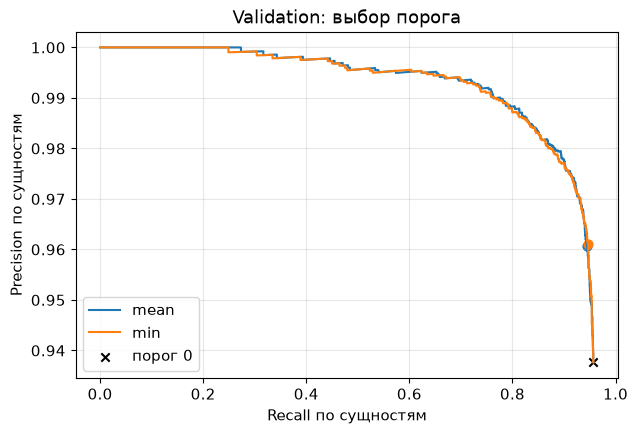

In [33]:
if '6.5' in BONUS_TASKS:
    from itertools import groupby

    def confidence_curve(gold, tags_list, probs_list, aggregate):
        gold_spans = [set(bio_to_spans(tags)) for tags in gold]
        support = sum(map(len, gold_spans))
        scored = sorted((
            (aggregate(probs[start:end]), (start, end, kind) in expected)
            for expected, tags, probs in zip(gold_spans, tags_list, probs_list, strict=True)
            for start, end, kind in bio_to_spans(tags)
        ), reverse=True)
        points = []
        true_positives = predicted = 0
        for threshold, tied in groupby(scored, key=lambda item: item[0]):
            for _, matched in tied:
                predicted += 1
                true_positives += matched
            points.append(dict(
                threshold=threshold, precision=true_positives / predicted,
                recall=true_positives / support if support else 0.0,
                f1_micro=2 * true_positives / (predicted + support),
            ))
        baseline = dict(points[-1], threshold=0.0) if points else dict(
            threshold=0.0, precision=0.0, recall=0.0, f1_micro=0.0,
        )
        return baseline, points

    def filter_spans(tags_list, probs_list, aggregate, threshold):
        return [spans_to_bio([
            (start, end, kind) for start, end, kind in bio_to_spans(tags)
            if aggregate(probs[start:end]) >= threshold
        ], len(tags)) for tags, probs in zip(tags_list, probs_list, strict=True)]

    val_tags, val_probs = predict_word_tags(model, val_tokens, batch_size=BATCH_SIZE, return_probs=True)
    assert val_tags == val_pred
    aggregations = {'mean': lambda probs: sum(probs) / len(probs), 'min': min}
    threshold_experiments = {}
    fig, ax = plt.subplots(figsize=(7, 4.5))
    for name, aggregate in aggregations.items():
        no_threshold, curve = confidence_curve(val_gold, val_tags, val_probs, aggregate)
        assert math.isclose(no_threshold['f1_micro'], validation_scores['f1_micro'], abs_tol=1e-12)
        best = max([no_threshold, *curve], key=lambda p: (p['f1_micro'], -p['threshold']))
        filtered = filter_spans(val_tags, val_probs, aggregate, best['threshold'])
        actual = entity_scores(val_gold, filtered)
        assert all(math.isclose(best[key], actual[key], abs_tol=1e-12)
                   for key in ('precision', 'recall', 'f1_micro'))
        threshold_experiments[name] = dict(best, delta_f1=best['f1_micro'] - no_threshold['f1_micro'])
        ax.plot([p['recall'] for p in curve], [p['precision'] for p in curve], label=name)
        ax.scatter(best['recall'], best['precision'], s=40)
        print(f'{name}: порог {best["threshold"]:.6f}, precision {best["precision"]:.4f}, '
              f'recall {best["recall"]:.4f}, micro-F1 {best["f1_micro"]:.4f}, '
              f'ΔF1 от порога 0: {100 * threshold_experiments[name]["delta_f1"]:+.2f} п.п.')

    ax.scatter(no_threshold['recall'], no_threshold['precision'], marker='x', color='black', label='порог 0')
    ax.set(xlabel='Recall по сущностям', ylabel='Precision по сущностям', title='Validation: выбор порога')
    ax.grid(alpha=0.3)
    ax.legend()
    plt.show()

    selected = max(threshold_experiments, key=lambda name: threshold_experiments[name]['f1_micro'])
    selected_threshold = threshold_experiments[selected]['threshold']
    test_tags, test_probs = predict_word_tags(model, test_tokens, batch_size=BATCH_SIZE, return_probs=True)
    test_filtered = filter_spans(test_tags, test_probs, aggregations[selected], selected_threshold)
    test_threshold_scores = entity_scores(test_gold, test_filtered)
    print(f'Выбрано на validation: {selected}, порог {selected_threshold:.6f}. '
          f'Test micro-F1: {final["f1_micro"]:.4f} → {test_threshold_scores["f1_micro"]:.4f}.')
    bonus_results['6.5'] = dict(
        validation_baseline=no_threshold, validation=threshold_experiments, selected=selected,
        test_baseline=entity_scores(test_gold, test_tags), test_filtered=test_threshold_scores,
    )

**Вопрос.** Какой порог дает лучший F1 и сколько он добавляет к порогу 0? Чем отличаются средняя и минимальная уверенность? Почему порог по уверенности не может поднять recall?

**Ответ.** На validation лучше всего сработала минимальная уверенность с порогом 0,750588. Micro-F1 0,9472 -> 0,9540. Лучший F1 при усреднении - 0,9530, при минимуме - 0,9540. Среднее позволяет более уверенным словам компенсировать одно слабое, а минимум оценивает весь спан по самому неуверенному слову. Повышение порога только убирает предсказанные спаны, поэтому число найденных правильных сущностей и recall могут только уменьшиться или остаться прежними. На test выбранный на validation порог дал 0,9505 -> 0,9532.

In [34]:
if bonus_results:
    metrics['bonus'] = bonus_results
    (ARTIFACTS / 'metrics.json').write_text(
        json.dumps(json_ready(metrics), ensure_ascii=False, indent=2), encoding='utf-8',
    )